# WindGuard (simple version): predicting wind-turbine failures from SCADA data

**Goal:** warn about a turbine failure up to 7 days before it happens, using the 10-minute sensor readings (temperatures, pressures, wind, power).

**How the notebook is organised.** Every code cell does one small job and shows one result (a table or a chart). Read it top to bottom:

| Part | What happens |
|---|---|
| 1. Data | create / load the data, make hourly tables |
| 2. EDA | look at the data: quality, stops, failures, power curve, correlations |
| 3. Labels | mark every hour as "pre-failure" (a failure follows within 7 days) or "normal" |
| 4. Features | turn raw sensors into "how far is this sensor from normal?" numbers |
| 5. Models | Logistic Regression, SVM, Naive Bayes, Random Forest, Gradient Boosting, ANN, Isolation Forest |
| 6. Evaluation | precision, recall, F1, PR-AUC, ROC-AUC, confusion matrix, confidence intervals, cross-validation |
| 7. Extras | remaining-useful-life, fused risk score, test on a second wind farm |
| 8-9. Save + export | summary tables, and the files the Streamlit dashboard reads |

**Data note.** This notebook runs on **synthetic** data (made by `windguard_synth.py`, included in the appendix). It reads the CSV files from your Google Drive (`USE_DRIVE = True`); the "demo" data has strong failure signals on purpose, so scores come out high. Always call these results **"simulation"**, never real-turbine performance.

## 1. Data
### 1.1 Settings

In [1]:
import os, re, glob, subprocess, sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

USE_DRIVE = True        # True  = read the CSV files from your Google Drive (folder below) | False = generate them inside Colab (see appendix)
SCENARIO = "demo"       # only used when USE_DRIVE = False: "demo" = strong failure signals | "realistic" = hard, weak signals

if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")                                   # asks you to allow access to your Drive
    except ImportError:
        pass                                                            # not in Colab: just use the path below
    DATA_ROOT = "/home/claude/drive_sim/WindGuard_Final_Deliverables"   # folder that contains Kelmarsh_synthetic_data_DEMO and Penmanshiel_synthetic_data_DEMO
    OUT = "/home/claude/simple/out2"                                        # result tables are saved here
else:
    DATA_ROOT = f"/content/windguard_synthetic_{SCENARIO}"
    OUT = "/content/windguard_outputs"
os.makedirs(OUT, exist_ok=True)

TRAIN_YEARS, VAL_YEAR, TEST_YEAR = [2016, 2017, 2018, 2019, 2020], 2021, 2022   # train / validation / test split by year
PRE_DAYS = 7            # an hour is "pre-failure" if a failure happens within the next 7 days
print("Reading data from:", DATA_ROOT)

Reading data from: /home/claude/drive_sim/WindGuard_Final_Deliverables


### 1.2 Check that the files are there

In [2]:
for farm in ["Kelmarsh", "Penmanshiel"]:
    n_scada = len(glob.glob(f"{DATA_ROOT}/**/{farm}_SCADA_*/Turbine_Data_*.csv", recursive=True))
    n_status = len(glob.glob(f"{DATA_ROOT}/**/{farm}_SCADA_*/Status_*.csv", recursive=True))
    print(f"{farm}: {n_scada} SCADA files, {n_status} status files")
if n_scada == 0:
    print("No files found. Check DATA_ROOT, or set USE_DRIVE = False and run the appendix at the bottom to generate the data.")

Kelmarsh: 42 SCADA files, 42 status files
Penmanshiel: 56 SCADA files, 56 status files


### 1.3 Which columns do we use?
* **Drivers** = operating conditions (wind, power, rotor speed, outside temperature). They explain why a part is warm or cold.
* **Sensors** = the component readings we watch for trouble (gearbox oil, bearings, stator, pressures, vibration).

In [3]:
DRIVERS = ["Wind speed (m/s)", "Power (kW)", "Rotor speed (RPM)", "Nacelle ambient temperature (°C)"]
SENSORS = ["Gear oil temperature (°C)", "Front bearing temperature (°C)", "Generator bearing front temperature (°C)",
           "Generator bearing rear temperature (°C)", "Stator temperature 1 (°C)", "Transformer temperature (°C)",
           "Nacelle temperature (°C)", "Gear oil inlet pressure (bar)", "Hydraulic oil pressure (bar)",
           "Tower Acceleration X (mm/ss)", "Tower Acceleration Y (mm/ss)", "Blade angle (pitch position) A (°)"]
WANTED = set(DRIVERS + SENSORS + ["Date and time"])
pd.DataFrame({"type": ["driver"] * len(DRIVERS) + ["sensor"] * len(SENSORS), "column": DRIVERS + SENSORS})

,type,column
0,driver,Wind speed (m/s)
1,driver,Power (kW)
2,driver,Rotor speed (RPM)
3,driver,Nacelle ambient temperature (°C)
4,sensor,Gear oil temperature (°C)
5,sensor,Front bearing temperature (°C)
6,sensor,Generator bearing front temperature (°C)
7,sensor,Generator bearing rear temperature (°C)
8,sensor,Stator temperature 1 (°C)
9,sensor,Transformer temperature (°C)


### 1.4 Helper functions to read the files
The CSV files start with a few comment lines, so we first find the line that holds the column names.

In [4]:
def read_with_header(path, header_start):
    with open(path, encoding="utf-8") as f:
        skip = next(i for i, line in enumerate(f) if line.startswith(header_start))
    df = pd.read_csv(path, skiprows=skip)
    df.columns = [c.replace("# ", "").strip() for c in df.columns]
    return df

def turbine_number(path):
    return int(re.search(r"_(\d+)_\d{4}-\d{2}-\d{2}_-_", os.path.basename(path)).group(1))

def load_farm(farm):
    """Return (hourly sensor table, status table) for one wind farm."""
    tables, stops = [], []
    for path in sorted(glob.glob(f"{DATA_ROOT}/**/{farm}_SCADA_*/Turbine_Data_*.csv", recursive=True)):
        df = read_with_header(path, "# Date and time")
        df = df[[c for c in df.columns if c in WANTED]]
        df["Date and time"] = pd.to_datetime(df["Date and time"])
        hourly = df.set_index("Date and time").resample("1h").mean()      # 10-minute readings -> hourly average
        hourly["turbine"] = turbine_number(path)
        tables.append(hourly.reset_index())
    for path in sorted(glob.glob(f"{DATA_ROOT}/**/{farm}_SCADA_*/Status_*.csv", recursive=True)):
        st = read_with_header(path, "# Timestamp start")
        st["turbine"] = turbine_number(path)
        stops.append(st)
    scada, status = pd.concat(tables, ignore_index=True), pd.concat(stops, ignore_index=True)
    status["Timestamp start"] = pd.to_datetime(status["Timestamp start"])
    status["Timestamp end"] = pd.to_datetime(status["Timestamp end"])
    return scada, status

### 1.5 Load Kelmarsh (the main farm)

In [5]:
kel, kel_status = load_farm("Kelmarsh")
print(f"Hourly sensor table: {kel.shape[0]:,} rows x {kel.shape[1]} columns | status log: {len(kel_status):,} events")
kel.head()

Hourly sensor table: 368,208 rows x 18 columns | status log: 1,287 events


,Date and time,Wind speed (m/s),Power (kW),Rotor speed (RPM),Nacelle ambient temperature (°C),Gear oil temperature (°C),Front bearing temperature (°C),Generator bearing front temperature (°C),Stator temperature 1 (°C),Blade angle (pitch position) A (°),Gear oil inlet pressure (bar),Hydraulic oil pressure (bar),Tower Acceleration X (mm/ss),Generator bearing rear temperature (°C),Transformer temperature (°C),Nacelle temperature (°C),Tower Acceleration Y (mm/ss),turbine
0,2016-01-01 00:00:00,6.126000,424.603000,9.163500,0.141667,26.565167,18.995667,20.372000,17.935500,1.073167,2.489833,171.038500,54.388833,21.440000,11.481333,6.148333,44.298500,1
1,2016-01-01 01:00:00,7.729333,681.711167,11.781333,1.257000,27.240000,22.262667,22.147167,22.777167,1.064833,2.634167,170.667833,62.607333,23.195333,11.624167,6.858333,49.066000,1
2,2016-01-01 02:00:00,8.897167,1105.490667,13.289500,1.767000,32.654667,27.502333,29.037833,35.837000,0.951667,2.723000,171.210833,67.666167,29.964000,15.913833,9.024167,54.364333,1
3,2016-01-01 03:00:00,8.872000,1167.259667,13.262000,1.060833,34.716333,28.836667,29.955000,37.236500,1.049333,2.660500,172.477000,70.409167,30.810167,18.024000,9.271167,58.108167,1
4,2016-01-01 04:00:00,6.351667,440.316833,10.928667,0.794333,31.866833,25.975500,24.310833,21.648333,1.024167,2.575333,171.885667,64.814500,25.427000,16.838667,7.757500,41.289667,1


## 2. Exploratory data analysis (EDA)
### 2.1 Data quality: how complete is the data?

In [6]:
quality = pd.DataFrame({
    "missing %": (kel[DRIVERS + SENSORS].isna().mean() * 100).round(2),
    "min": kel[DRIVERS + SENSORS].min().round(1),
    "max": kel[DRIVERS + SENSORS].max().round(1)})
print(f"{kel.turbine.nunique()} turbines, {kel['Date and time'].min():%Y-%m-%d} to {kel['Date and time'].max():%Y-%m-%d}")
quality

6 turbines, 2016-01-01 to 2022-12-31


,missing %,min,max
Wind speed (m/s),0.86,0.0,24.0
Power (kW),0.86,-13.4,2101.8
Rotor speed (RPM),0.86,0.0,15.0
Nacelle ambient temperature (°C),0.86,-9.5,29.3
Gear oil temperature (°C),0.86,9.6,109.1
Front bearing temperature (°C),0.86,0.6,81.2
Generator bearing front temperature (°C),0.86,4.1,103.9
Generator bearing rear temperature (°C),0.86,5.1,81.3
Stator temperature 1 (°C),0.86,3.3,147.0
Transformer temperature (°C),0.86,-2.6,109.3


### 2.2 Why does the turbine stop? (status log)

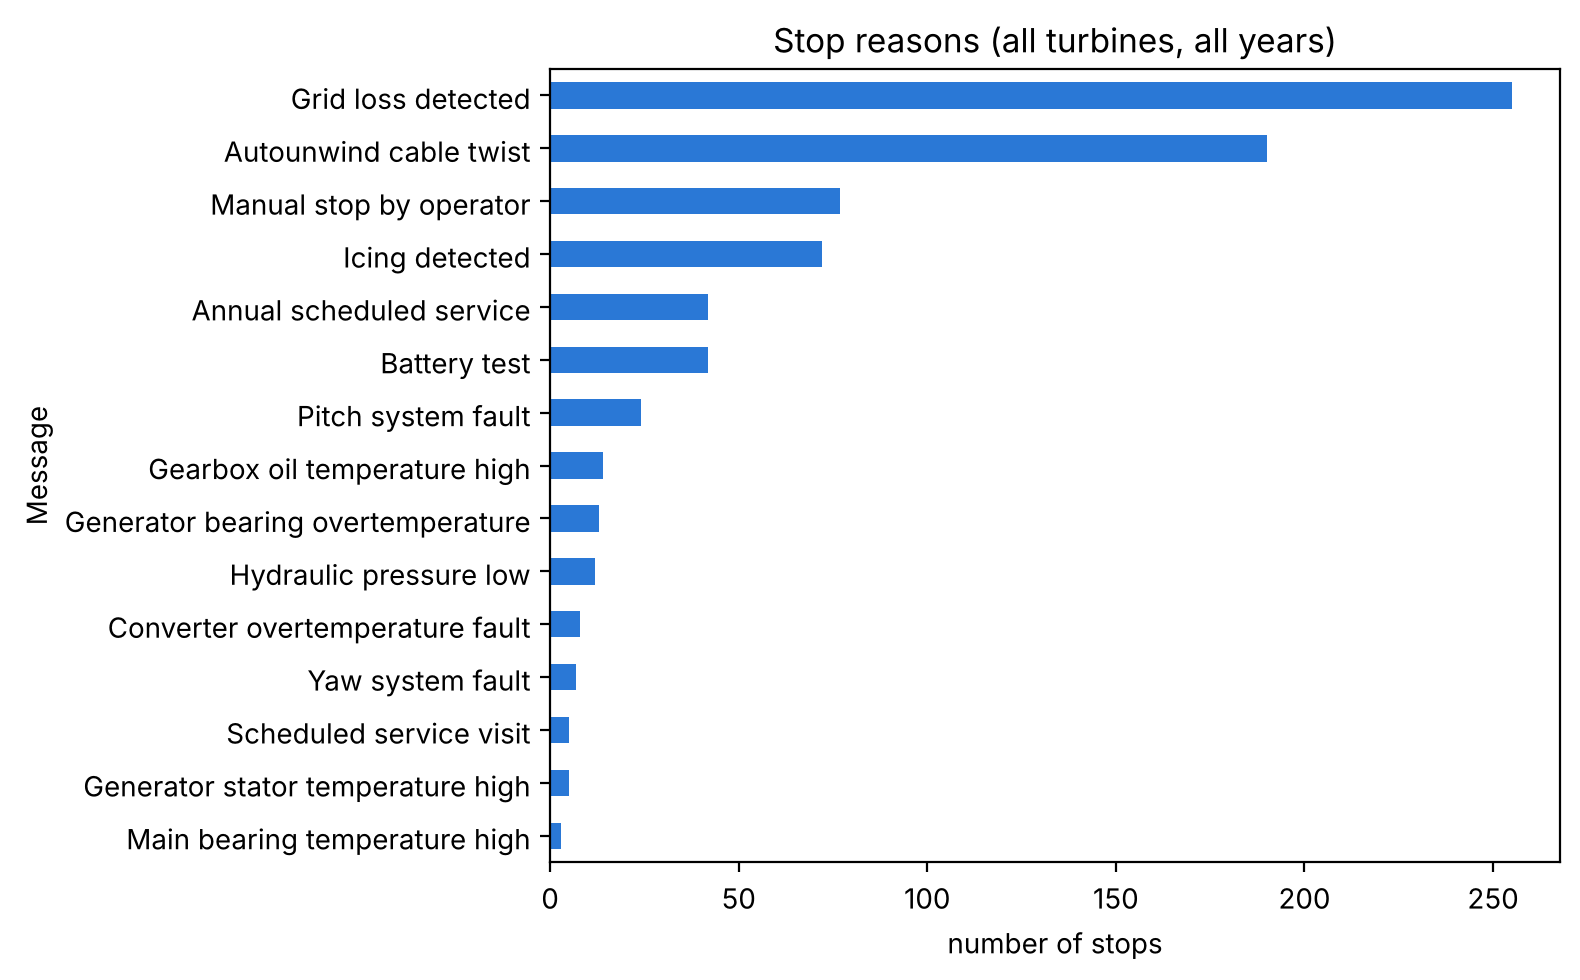

In [7]:
stop_reasons = kel_status[kel_status["Status"] == "Stop"]["Message"].value_counts()
stop_reasons.sort_values().plot.barh(figsize=(8, 5), color="#2a78d6")
plt.xlabel("number of stops"); plt.title("Stop reasons (all turbines, all years)"); plt.tight_layout(); plt.show()

### 2.3 Power curve: power produced for each wind speed
A healthy turbine follows one clean curve; the cut-in is near 3 m/s and the rated power is 2050 kW.

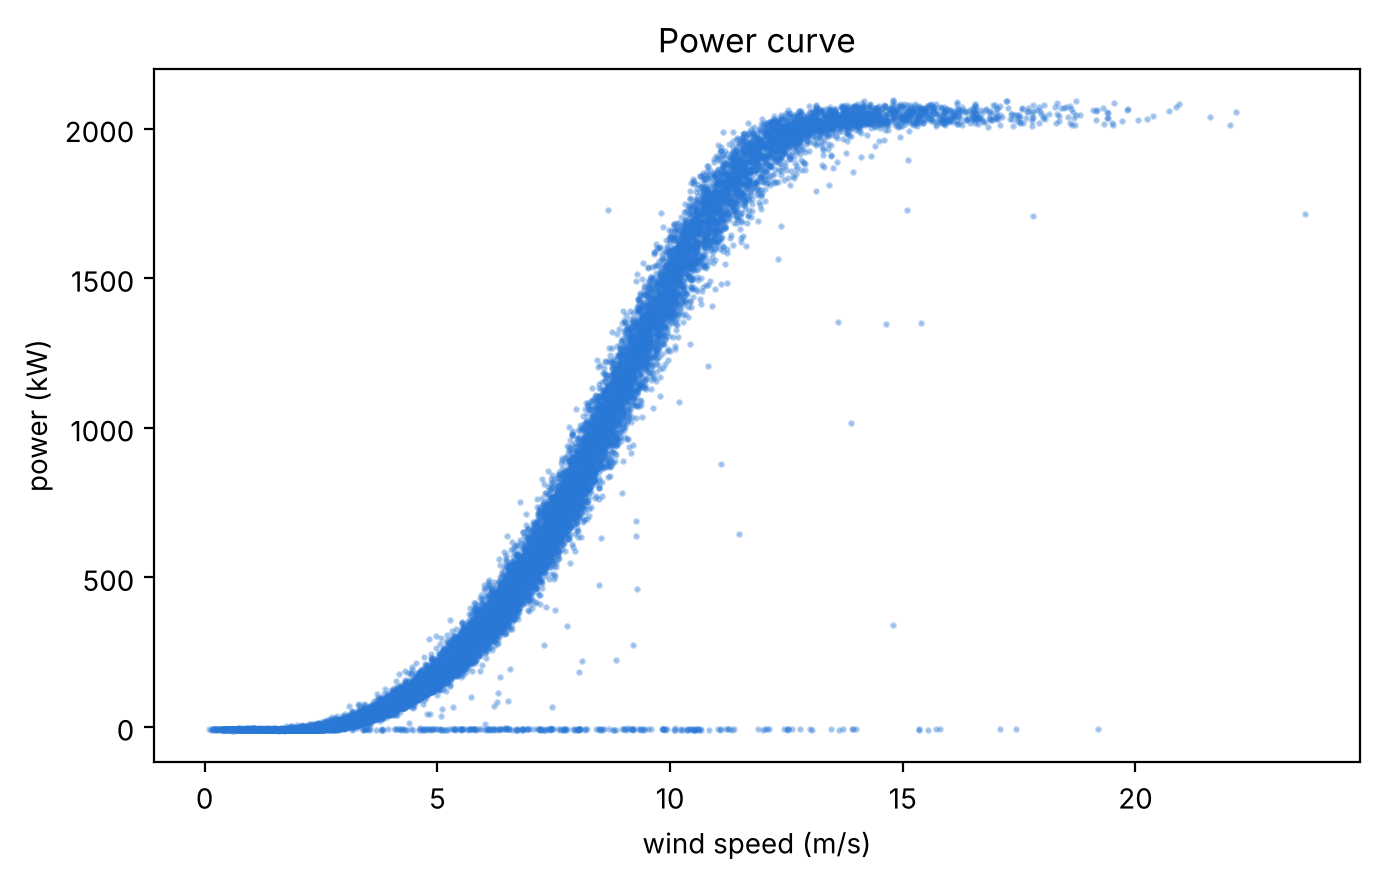

In [8]:
s = kel.dropna(subset=["Wind speed (m/s)", "Power (kW)"]).sample(20000, random_state=0)
plt.figure(figsize=(7, 4.5))
plt.scatter(s["Wind speed (m/s)"], s["Power (kW)"], s=2, alpha=0.3, color="#2a78d6")
plt.xlabel("wind speed (m/s)"); plt.ylabel("power (kW)"); plt.title("Power curve"); plt.tight_layout(); plt.show()

### 2.4 Correlation between sensors
Blocks of high correlation mean sensors move together (usually because they all follow the load).

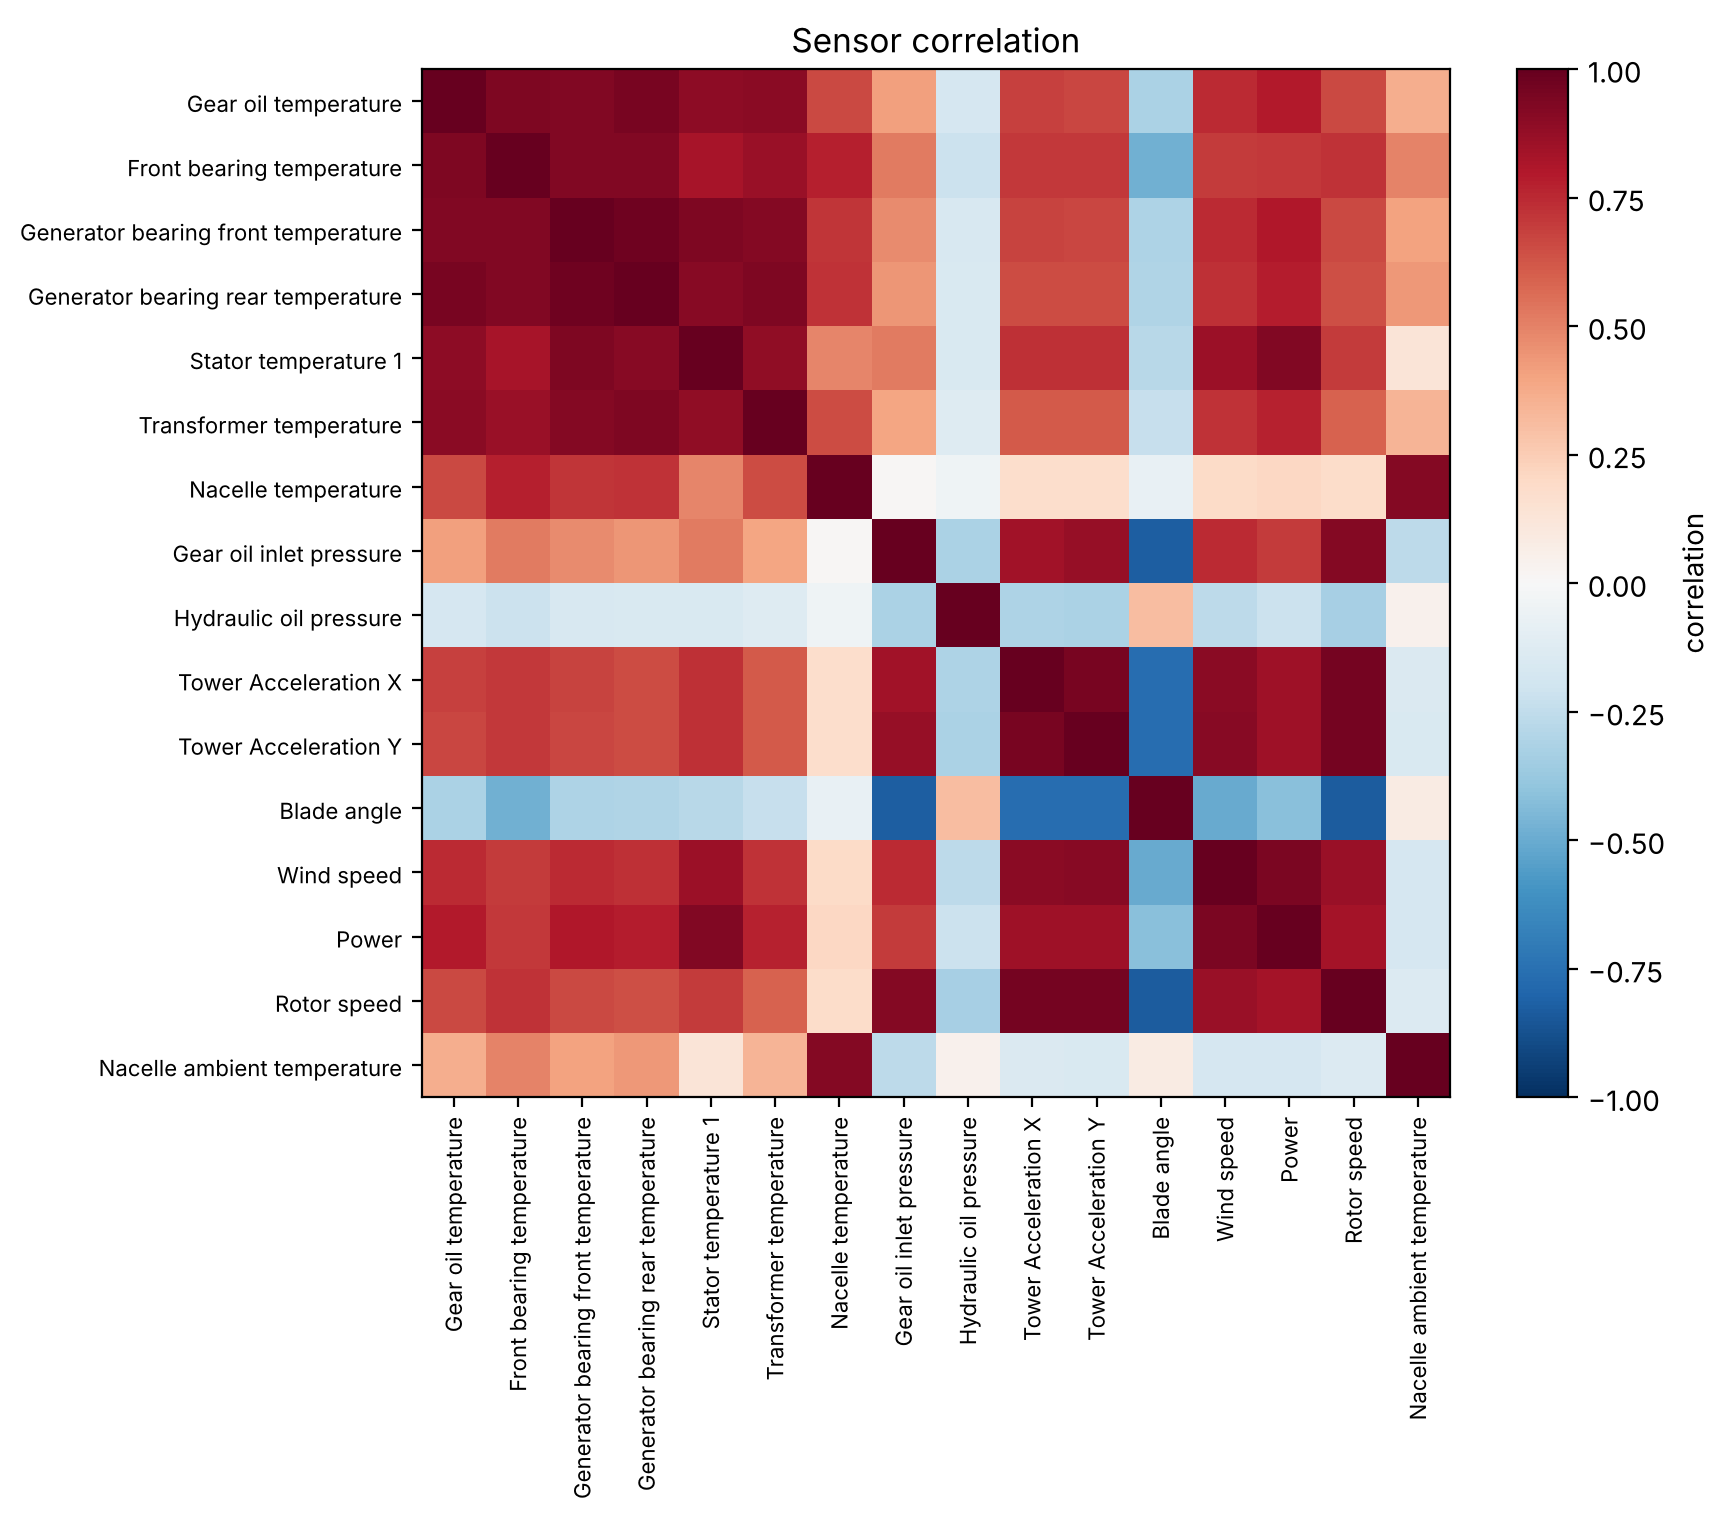

In [9]:
corr = kel[SENSORS + DRIVERS].corr()
plt.figure(figsize=(9, 7.5))
plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.xticks(range(len(corr)), [c.split(" (")[0] for c in corr.columns], rotation=90, fontsize=8)
plt.yticks(range(len(corr)), [c.split(" (")[0] for c in corr.columns], fontsize=8)
plt.colorbar(label="correlation"); plt.title("Sensor correlation"); plt.tight_layout(); plt.show()

## 3. Labels: which hours come before a failure?
### 3.1 Find the failures
Rule used here (simple and easy to change): a **failure** is a status event with `Status = Stop` and `IEC category = Forced outage`. Stops of the same turbine less than 7 days apart count as one failure.

In [10]:
def find_failures(status):
    stops = status[(status["Status"] == "Stop") & (status["IEC category"] == "Forced outage")]
    stops = stops.sort_values(["turbine", "Timestamp start"]).copy()
    gap = stops.groupby("turbine")["Timestamp start"].diff()
    stops["episode"] = (gap.isna() | (gap > pd.Timedelta(days=7))).cumsum()       # new failure when the gap is > 7 days
    return stops.groupby("episode").agg(turbine=("turbine", "first"), t_fail=("Timestamp start", "first"),
                                        t_end=("Timestamp end", "last"), message=("Message", "first")).reset_index(drop=True)

kel_failures = find_failures(kel_status)
print(len(kel_failures), "failures found")
kel_failures.groupby(kel_failures.t_fail.dt.year).size().rename("failures per year").to_frame().T

85 failures found


t_fail,2016,2017,2018,2019,2020,2021,2022
failures per year,5,11,13,12,16,15,13


### 3.2 When did the failures happen?

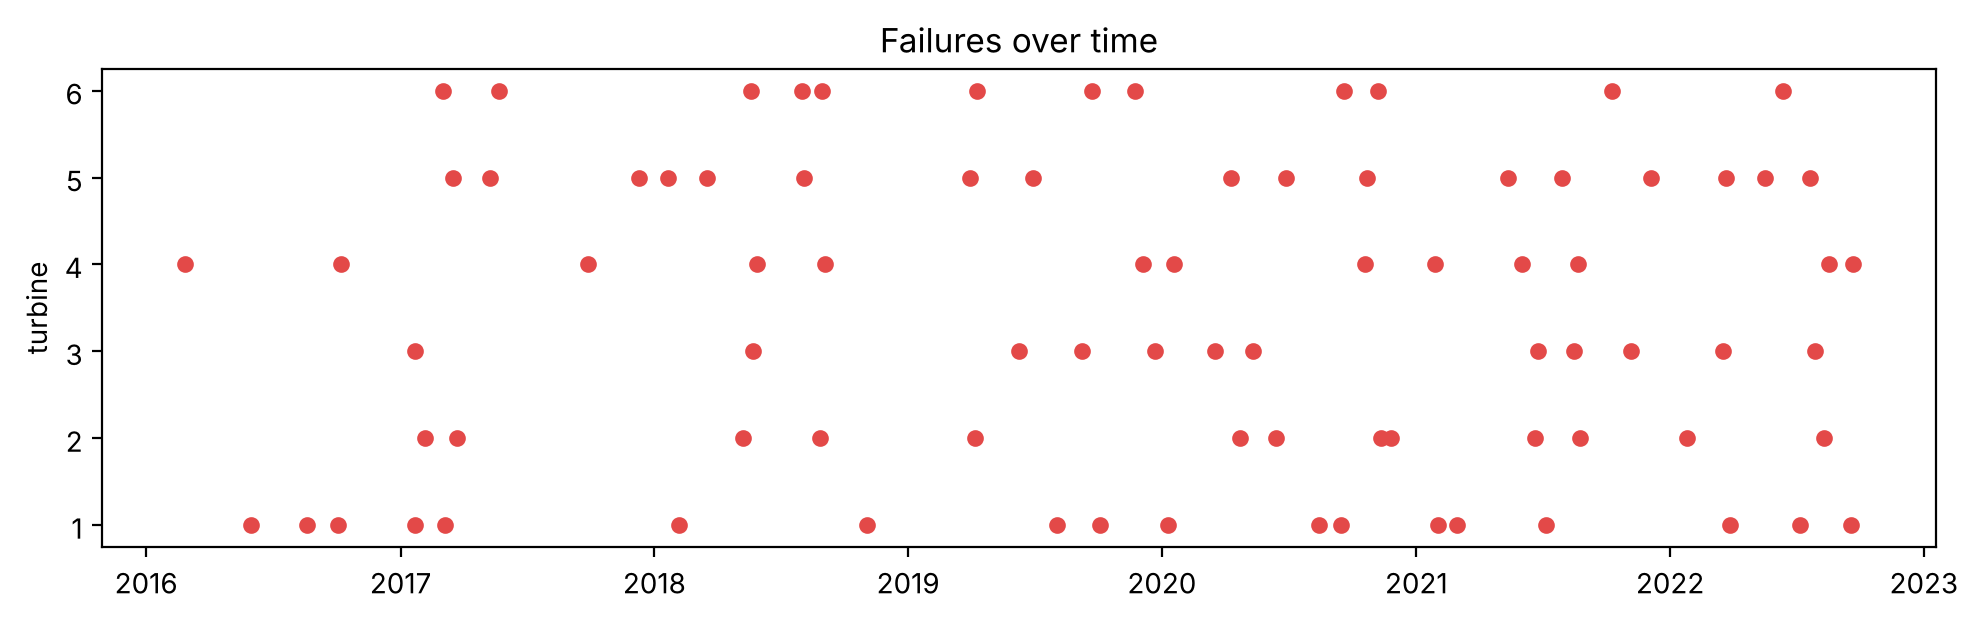

In [11]:
plt.figure(figsize=(10, 3.2))
plt.scatter(kel_failures.t_fail, kel_failures.turbine, s=25, color="#e34948")
plt.yticks(sorted(kel_failures.turbine.unique())); plt.ylabel("turbine"); plt.title("Failures over time"); plt.tight_layout(); plt.show()

### 3.3 Label every hour
* `label = 1` (pre-failure): the next failure is less than 7 days away.
* `label = 0` (normal): everything else.
* **Skipped** hours: the turbine is stopped (any stop) or it is the first day after a failure; sensor values there are not meaningful.

In [12]:
def add_labels(scada, failures, status):
    scada = scada.sort_values(["turbine", "Date and time"]).reset_index(drop=True)
    scada["label"], scada["episode"], scada["days_to_failure"], scada["skip"] = 0, -1, np.nan, False
    for turbine, rows in scada.groupby("turbine"):
        t, idx = rows["Date and time"], rows.index
        for _, st in status[(status.turbine == turbine) & (status.Status == "Stop")].iterrows():
            scada.loc[idx[((t + pd.Timedelta(hours=1) > st["Timestamp start"]) & (t < st["Timestamp end"])).to_numpy()], "skip"] = True
        for episode, f in failures[failures.turbine == turbine].iterrows():
            window = ((t >= f.t_fail - pd.Timedelta(days=PRE_DAYS)) & (t < f.t_fail)).to_numpy()
            scada.loc[idx[window], "label"] = 1
            scada.loc[idx[window], "episode"] = episode
            scada.loc[idx[window], "days_to_failure"] = (f.t_fail - t[window]).dt.total_seconds() / 86400
            after = ((t >= f.t_fail) & (t < f.t_end + pd.Timedelta(days=1))).to_numpy()      # stopped + one extra day
            scada.loc[idx[after], "skip"] = True
    return scada

kel = add_labels(kel, kel_failures, kel_status)
usable = kel[~kel.skip]
usable.groupby(usable["Date and time"].dt.year).agg(hours=("label", "size"), pre_failure_hours=("label", "sum"),
                                                      pre_failure_pct=("label", lambda x: round(x.mean() * 100, 1)))

,hours,pre_failure_hours,pre_failure_pct
Date and time,,,
2016,52059,835,1.6
2017,51489,1829,3.6
2018,51171,2145,4.2
2019,51324,1999,3.9
2020,51302,2658,5.2
2021,51246,2480,4.8
2022,50980,2153,4.2


### 3.4 What does a failure look like in the raw data?
Gearbox oil temperature in the 14 days before one gearbox failure. The vertical line is the failure.

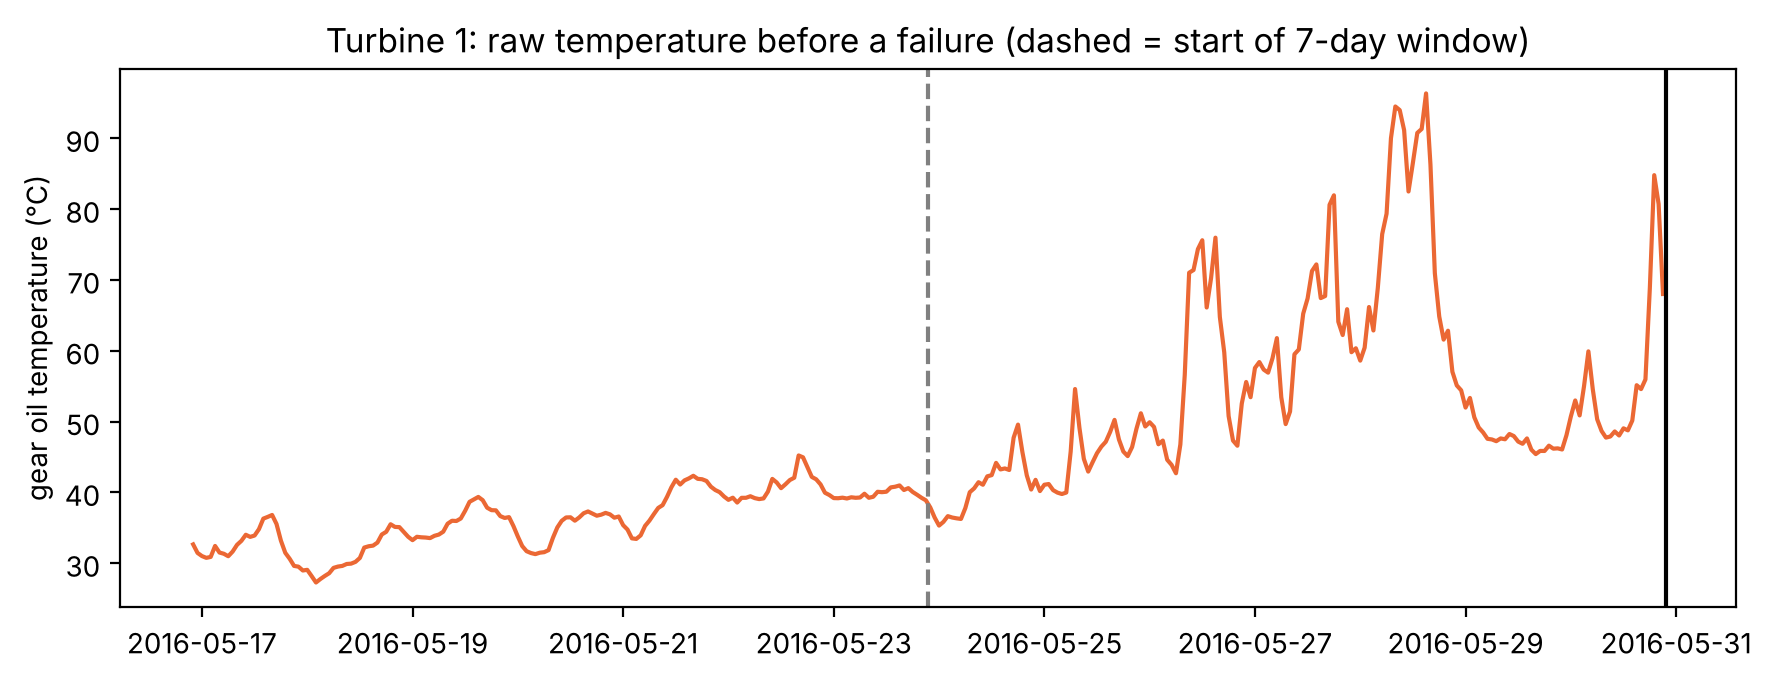

In [13]:
f = kel_failures[kel_failures.message.str.contains("Gearbox")].iloc[0]
w = kel[(kel.turbine == f.turbine) & (kel["Date and time"] > f.t_fail - pd.Timedelta(days=14)) & (kel["Date and time"] <= f.t_fail)]
plt.figure(figsize=(9, 3.5))
plt.plot(w["Date and time"], w["Gear oil temperature (°C)"], color="#eb6834")
plt.axvline(f.t_fail, color="k"); plt.axvline(f.t_fail - pd.Timedelta(days=PRE_DAYS), color="grey", ls="--")
plt.ylabel("gear oil temperature (°C)"); plt.title(f"Turbine {f.turbine}: raw temperature before a failure (dashed = start of 7-day window)")
plt.tight_layout(); plt.show()

## 4. Features: "how far is each sensor from normal?"
A gearbox can run hot just because it is windy. So we first learn what each sensor *should* read for the current wind, power, rotor speed and outside temperature (a **normal-behaviour model**), then use the **difference** (actual minus expected) as the signal. A rising difference means something is changing inside the machine.

### 4.1 Normal-behaviour model

In [14]:
from sklearn.ensemble import HistGradientBoostingRegressor

kel["power_mean_6h"] = kel.groupby("turbine")["Power (kW)"].transform(lambda s: s.rolling(6, min_periods=3).mean())
DRIVER_COLS = DRIVERS + ["power_mean_6h"]                 # inputs of the normal-behaviour model

def fit_normal_model(df, sensors):
    """One small model per sensor, trained on normal hours only."""
    df = df.dropna(subset=DRIVER_COLS)
    df = df.sample(min(len(df), 100_000), random_state=0)
    models = {}
    for s in sensors:
        rows = df.dropna(subset=[s])
        models[s] = HistGradientBoostingRegressor(max_iter=100, max_depth=6).fit(rows[DRIVER_COLS], rows[s])
    return models

is_train = kel["Date and time"].dt.year.isin(TRAIN_YEARS)
healthy_train = kel[is_train & (kel.label == 0) & ~kel.skip]
normal_model = fit_normal_model(healthy_train, SENSORS)
print("Trained", len(normal_model), "normal-behaviour models on", f"{len(healthy_train):,}", "normal training hours")

Trained 12 normal-behaviour models on 247,879 normal training hours


### 4.2 Residuals (actual minus expected)
Each turbine gets its own small correction so that turbine-to-turbine offsets do not count as problems.

In [15]:
def get_residuals(df, models, sensors):
    res = pd.DataFrame(index=df.index, columns=sensors, dtype="float64")
    ok = df[DRIVER_COLS].notna().all(axis=1)
    for s in sensors:
        res.loc[ok, s] = df.loc[ok, s] - models[s].predict(df.loc[ok, DRIVER_COLS])
    res[df["skip"]] = np.nan                                  # ignore stopped hours
    return res

kel_res = get_residuals(kel, normal_model, SENSORS)
offset = kel_res[is_train & (kel.label == 0)].groupby(kel.turbine).median()      # each turbine's own normal offset
kel_res = kel_res - offset.reindex(kel.turbine).to_numpy()
kel_res.describe().loc[["mean", "std"]].round(2).T.rename(columns={"mean": "mean residual", "std": "std residual"})

,mean residual,std residual
Gear oil temperature (°C),0.23,2.02
Front bearing temperature (°C),0.04,1.17
Generator bearing front temperature (°C),0.15,1.60
Generator bearing rear temperature (°C),0.07,1.15
Stator temperature 1 (°C),0.12,1.73
Transformer temperature (°C),0.10,1.97
Nacelle temperature (°C),0.00,0.45
Gear oil inlet pressure (bar),-0.01,0.08
Hydraulic oil pressure (bar),-0.21,3.94
Tower Acceleration X (mm/ss),0.38,4.79


### 4.3 The same failure, as residuals
The residual stays near 0 while the machine is healthy and rises towards the failure, much clearer than the raw temperature above.

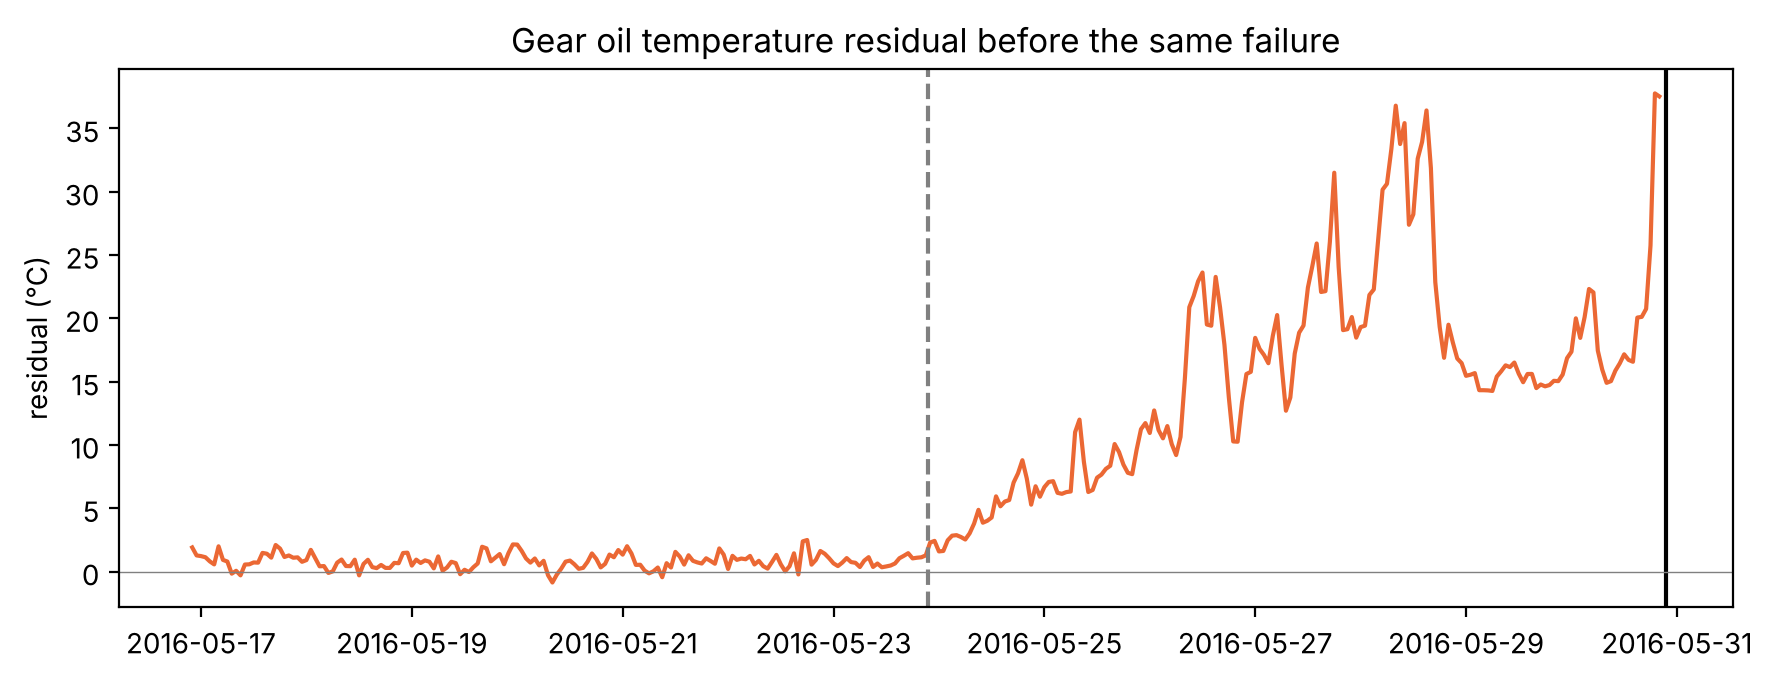

In [16]:
w_idx = w.index
plt.figure(figsize=(9, 3.5))
plt.plot(kel.loc[w_idx, "Date and time"], kel_res.loc[w_idx, "Gear oil temperature (°C)"], color="#eb6834")
plt.axvline(f.t_fail, color="k"); plt.axvline(f.t_fail - pd.Timedelta(days=PRE_DAYS), color="grey", ls="--"); plt.axhline(0, color="grey", lw=0.5)
plt.ylabel("residual (°C)"); plt.title("Gear oil temperature residual before the same failure"); plt.tight_layout(); plt.show()

### 4.4 Build the feature table
For every sensor: the residual now, its average over the last 6 hours, and over the last 24 hours (short averages remove noise).

In [17]:
def make_features(res, df):
    feats = {}
    for s in res.columns:
        feats[f"{s}__now"] = res[s]
        feats[f"{s}__6h"] = res[s].groupby(df["turbine"]).transform(lambda x: x.rolling(6, min_periods=3).mean())
        feats[f"{s}__24h"] = res[s].groupby(df["turbine"]).transform(lambda x: x.rolling(24, min_periods=12).mean())
    feats["power_pct"] = df["Power (kW)"] / 2050 * 100        # how loaded the turbine is
    return pd.DataFrame(feats).fillna(0)                      # missing = no deviation from normal

X = make_features(kel_res, kel)
print("Feature table:", X.shape[0], "rows x", X.shape[1], "features")
X.iloc[:, :6].describe().round(2)

Feature table: 368208 rows x 37 features


,Gear oil temperature (°C)__now,Gear oil temperature (°C)__6h,Gear oil temperature (°C)__24h,Front bearing temperature (°C)__now,Front bearing temperature (°C)__6h,Front bearing temperature (°C)__24h
count,368208.00,368208.00,368208.00,368208.00,368208.00,368208.00
mean,0.22,0.22,0.22,0.04,0.04,0.04
std,1.98,1.70,1.60,1.15,0.82,0.71
min,-10.10,-6.28,-2.67,-10.33,-5.28,-2.04
25%,-0.69,-0.47,-0.39,-0.60,-0.33,-0.19
50%,0.01,0.01,0.00,0.00,0.00,0.00
75%,0.91,0.66,0.56,0.62,0.33,0.18
max,53.12,50.96,44.50,38.49,37.88,35.80


### 4.5 Split by year and scale
Train = 2016-2020, validation = 2021 (to choose thresholds), test = 2022 (final report, never used for tuning). Scaling uses normal training hours only.

In [18]:
from sklearn.preprocessing import StandardScaler

year = kel["Date and time"].dt.year
use = ~kel.skip
tr, va, te = (use & year.isin(TRAIN_YEARS)).to_numpy(), (use & (year == VAL_YEAR)).to_numpy(), (use & (year == TEST_YEAR)).to_numpy()

scaler = StandardScaler().fit(X[tr & (kel.label == 0).to_numpy()])
Z = np.clip(scaler.transform(X), -8, 8)
y = kel["label"].to_numpy()
meta = kel[["turbine", "Date and time", "label", "episode", "days_to_failure"]]
Z_tr, y_tr, Z_va, y_va, Z_te, y_te = Z[tr], y[tr], Z[va], y[va], Z[te], y[te]

pd.DataFrame({"hours": [tr.sum(), va.sum(), te.sum()], "pre-failure hours": [y_tr.sum(), y_va.sum(), y_te.sum()],
              "pre-failure %": [round(y_tr.mean() * 100, 1), round(y_va.mean() * 100, 1), round(y_te.mean() * 100, 1)]},
             index=["train (2016-2020)", "validation (2021)", "test (2022)"])

,hours,pre-failure hours,pre-failure %
train (2016-2020),257345,9466,3.7
validation (2021),51246,2480,4.8
test (2022),50980,2153,4.2


### 4.6 PCA and Kernel PCA (2-D view of the features)
If failures separate from normal hours in this picture, the features carry a real signal.

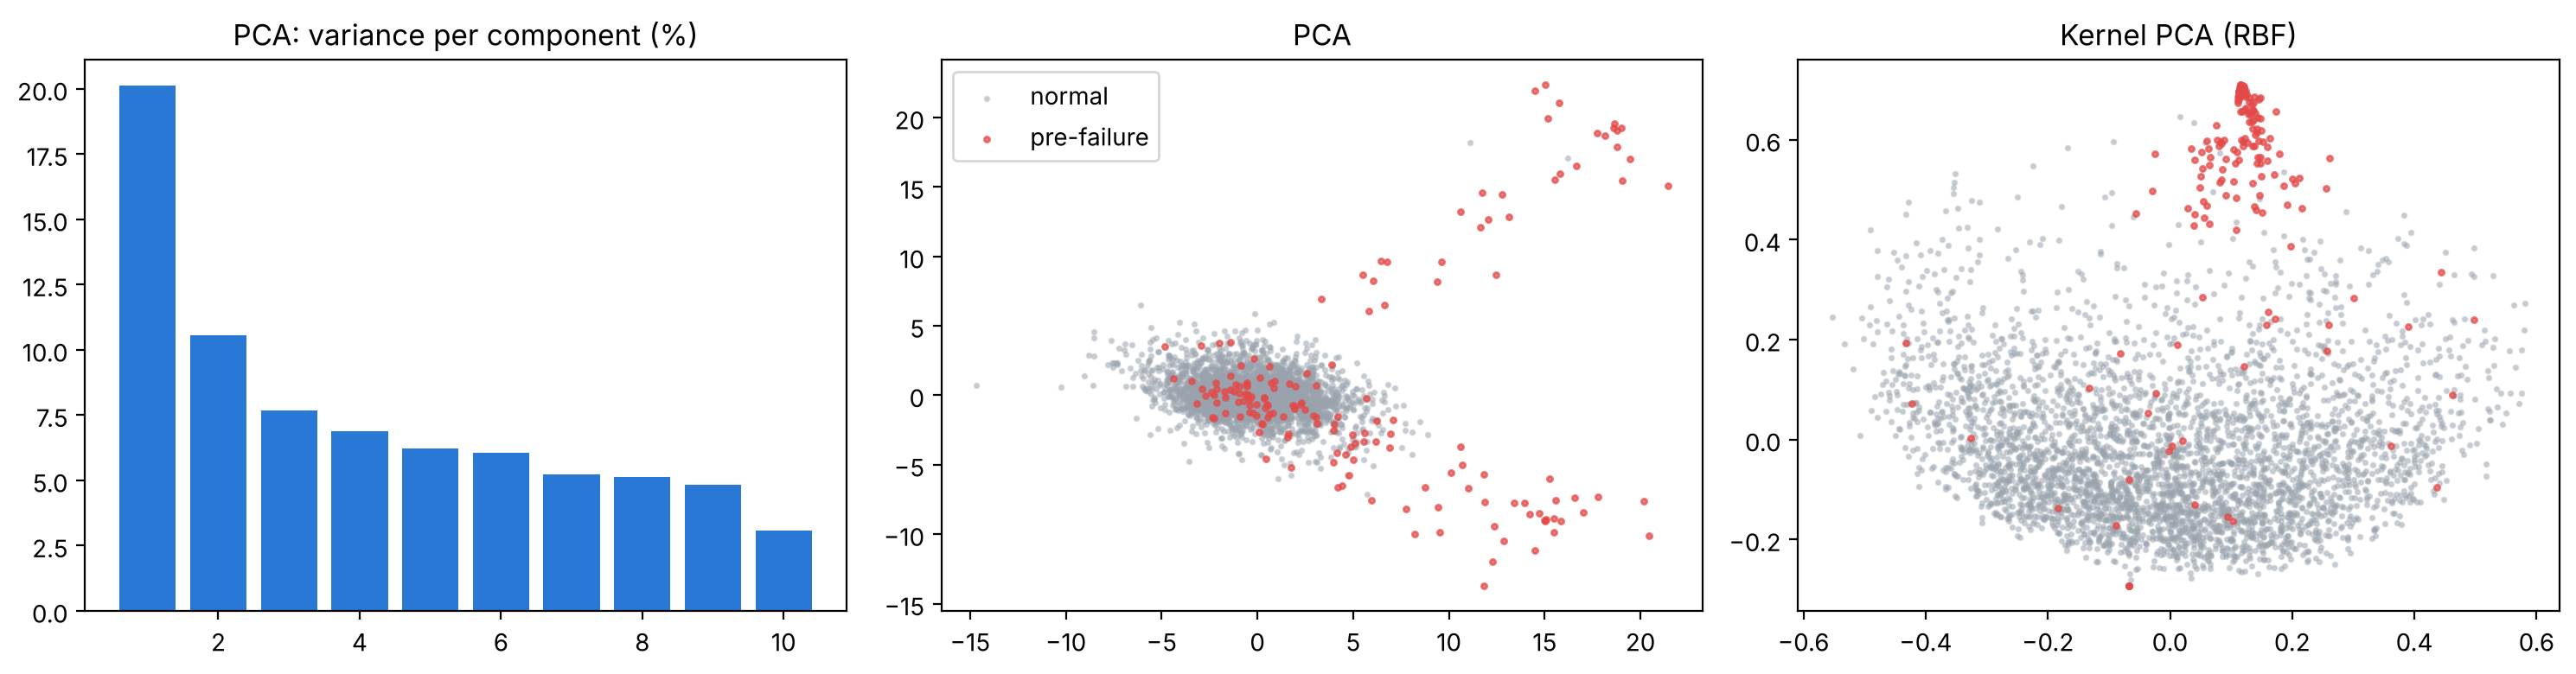

In [19]:
from sklearn.decomposition import PCA, KernelPCA

pick = np.random.RandomState(0).choice(len(Z_tr), 4000, replace=False)
pca = PCA(n_components=10).fit(Z_tr[pick])
p2 = pca.transform(Z_tr[pick])[:, :2]
k2 = KernelPCA(n_components=2, kernel="rbf", gamma=0.01).fit_transform(Z_tr[pick])
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].bar(range(1, 11), pca.explained_variance_ratio_ * 100, color="#2a78d6"); ax[0].set_title("PCA: variance per component (%)")
for a, pts, name in [(ax[1], p2, "PCA"), (ax[2], k2, "Kernel PCA (RBF)")]:
    a.scatter(pts[y_tr[pick] == 0, 0], pts[y_tr[pick] == 0, 1], s=3, alpha=0.4, label="normal", color="#9aa3ad")
    a.scatter(pts[y_tr[pick] == 1, 0], pts[y_tr[pick] == 1, 1], s=5, alpha=0.7, label="pre-failure", color="#e34948"); a.set_title(name)
ax[1].legend(); plt.tight_layout(); plt.show()

## 5. Models
### 5.1 Evaluation helpers
* We pick each model's **alert threshold on the validation year (2021)**: the score that gives the best F1.
* Then we measure the **test year (2022)** with that fixed threshold.
* **Precision** = of the hours we flag, how many are truly pre-failure. **Recall** = of the truly pre-failure hours, how many we flag.

In [20]:
from sklearn.metrics import (precision_recall_curve, average_precision_score, roc_auc_score, precision_score, recall_score, f1_score)

results, scores, thresholds = [], {}, {}

def best_threshold(y_true, score):
    prec, rec, thr = precision_recall_curve(y_true, score)
    f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
    return thr[np.argmax(f1)]

def evaluate(name, score_va, score_te):
    thr = best_threshold(y_va, score_va)
    alert = score_te >= thr
    row = dict(model=name, precision=precision_score(y_te, alert), recall=recall_score(y_te, alert), f1=f1_score(y_te, alert),
               pr_auc=average_precision_score(y_te, score_te), roc_auc=roc_auc_score(y_te, score_te))
    results.append(row); scores[name] = (score_va, score_te); thresholds[name] = thr
    return pd.DataFrame([row]).set_index("model").round(3)

### 5.2 Logistic Regression
A straight-line model: each feature gets a weight. Simple and fast.

In [21]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(class_weight="balanced", max_iter=300).fit(Z_tr, y_tr)
evaluate("Logistic Regression", lr.predict_proba(Z_va)[:, 1], lr.predict_proba(Z_te)[:, 1])

,precision,recall,f1,pr_auc,roc_auc
model,,,,,
Logistic Regression,0.853,0.699,0.768,0.687,0.934


### 5.3 Support Vector Machine (linear)
Finds the line that best separates pre-failure from normal hours.

In [22]:
from sklearn.linear_model import SGDClassifier
svm = SGDClassifier(loss="hinge", class_weight="balanced", random_state=0).fit(Z_tr, y_tr)
evaluate("SVM (linear)", svm.decision_function(Z_va), svm.decision_function(Z_te))

,precision,recall,f1,pr_auc,roc_auc
model,,,,,
SVM (linear),0.871,0.669,0.757,0.737,0.942


### 5.4 Gaussian Naive Bayes
Assumes each feature is bell-shaped within each class and combines them with Bayes' rule.

In [23]:
from sklearn.naive_bayes import GaussianNB
nb = GaussianNB().fit(Z_tr, y_tr)
evaluate("Naive Bayes", nb.predict_proba(Z_va)[:, 1], nb.predict_proba(Z_te)[:, 1])

,precision,recall,f1,pr_auc,roc_auc
model,,,,,
Naive Bayes,0.79,0.753,0.771,0.697,0.916


### 5.5 Random Forest
Many decision trees voting together; handles non-linear patterns.

In [24]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=5, class_weight="balanced_subsample",
                            n_jobs=-1, random_state=0).fit(Z_tr, y_tr)
evaluate("Random Forest", rf.predict_proba(Z_va)[:, 1], rf.predict_proba(Z_te)[:, 1])

,precision,recall,f1,pr_auc,roc_auc
model,,,,,
Random Forest,0.865,0.808,0.836,0.785,0.952


### 5.6 Gradient Boosting
Trees built one after another, each fixing the mistakes of the previous ones.

In [25]:
from sklearn.ensemble import HistGradientBoostingClassifier
gb = HistGradientBoostingClassifier(max_iter=200, max_depth=4, learning_rate=0.1, class_weight="balanced", random_state=0).fit(Z_tr, y_tr)
evaluate("Gradient Boosting", gb.predict_proba(Z_va)[:, 1], gb.predict_proba(Z_te)[:, 1])

,precision,recall,f1,pr_auc,roc_auc
model,,,,,
Gradient Boosting,0.855,0.773,0.812,0.744,0.953


### 5.7 Neural network (ANN)
Two hidden layers (64 and 32 neurons). Normal hours are down-sampled to 3 per failure hour because the network has no class-weight option.

In [26]:
from sklearn.neural_network import MLPClassifier
rng = np.random.RandomState(0)
pos, neg = np.flatnonzero(y_tr == 1), np.flatnonzero(y_tr == 0)
keep = np.concatenate([pos, rng.choice(neg, 3 * len(pos), replace=False)])
ann = MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=200, random_state=0).fit(Z_tr[keep], y_tr[keep])
evaluate("ANN (64-32)", ann.predict_proba(Z_va)[:, 1], ann.predict_proba(Z_te)[:, 1])

,precision,recall,f1,pr_auc,roc_auc
model,,,,,
ANN (64-32),0.872,0.769,0.818,0.777,0.941


### 5.8 Isolation Forest (unsupervised)
Never sees the labels: it only learns what normal looks like and scores how unusual each hour is.

In [27]:
from sklearn.ensemble import IsolationForest
iso = IsolationForest(n_estimators=150, random_state=0, n_jobs=-1).fit(Z_tr[y_tr == 0])
evaluate("Isolation Forest", -iso.score_samples(Z_va), -iso.score_samples(Z_te))

,precision,recall,f1,pr_auc,roc_auc
model,,,,,
Isolation Forest,0.379,0.388,0.383,0.381,0.822


### 5.9 Fused risk score
Average of the Logistic Regression, Random Forest and Gradient Boosting probabilities. Averaging models usually makes the alert steadier.

In [28]:
fuse = lambda i: np.mean([scores[m][i] for m in ["Logistic Regression", "Random Forest", "Gradient Boosting"]], axis=0)
evaluate("Fused risk score", fuse(0), fuse(1))

,precision,recall,f1,pr_auc,roc_auc
model,,,,,
Fused risk score,0.855,0.824,0.839,0.767,0.962


## 6. Evaluation
### 6.1 All models side by side (test year 2022)

In [29]:
comparison = pd.DataFrame(results).set_index("model").sort_values("pr_auc", ascending=False).round(3)
comparison.to_csv(f"{OUT}/model_comparison_test.csv")
print(f"No-skill level: PR-AUC is about {y_te.mean():.3f} (the share of pre-failure hours in the test year)")
comparison

No-skill level: PR-AUC is about 0.042 (the share of pre-failure hours in the test year)


,precision,recall,f1,pr_auc,roc_auc
model,,,,,
Random Forest,0.865,0.808,0.836,0.785,0.952
ANN (64-32),0.872,0.769,0.818,0.777,0.941
Fused risk score,0.855,0.824,0.839,0.767,0.962
Gradient Boosting,0.855,0.773,0.812,0.744,0.953
SVM (linear),0.871,0.669,0.757,0.737,0.942
Naive Bayes,0.790,0.753,0.771,0.697,0.916
Logistic Regression,0.853,0.699,0.768,0.687,0.934
Isolation Forest,0.379,0.388,0.383,0.381,0.822


### 6.2 Precision-recall and ROC curves

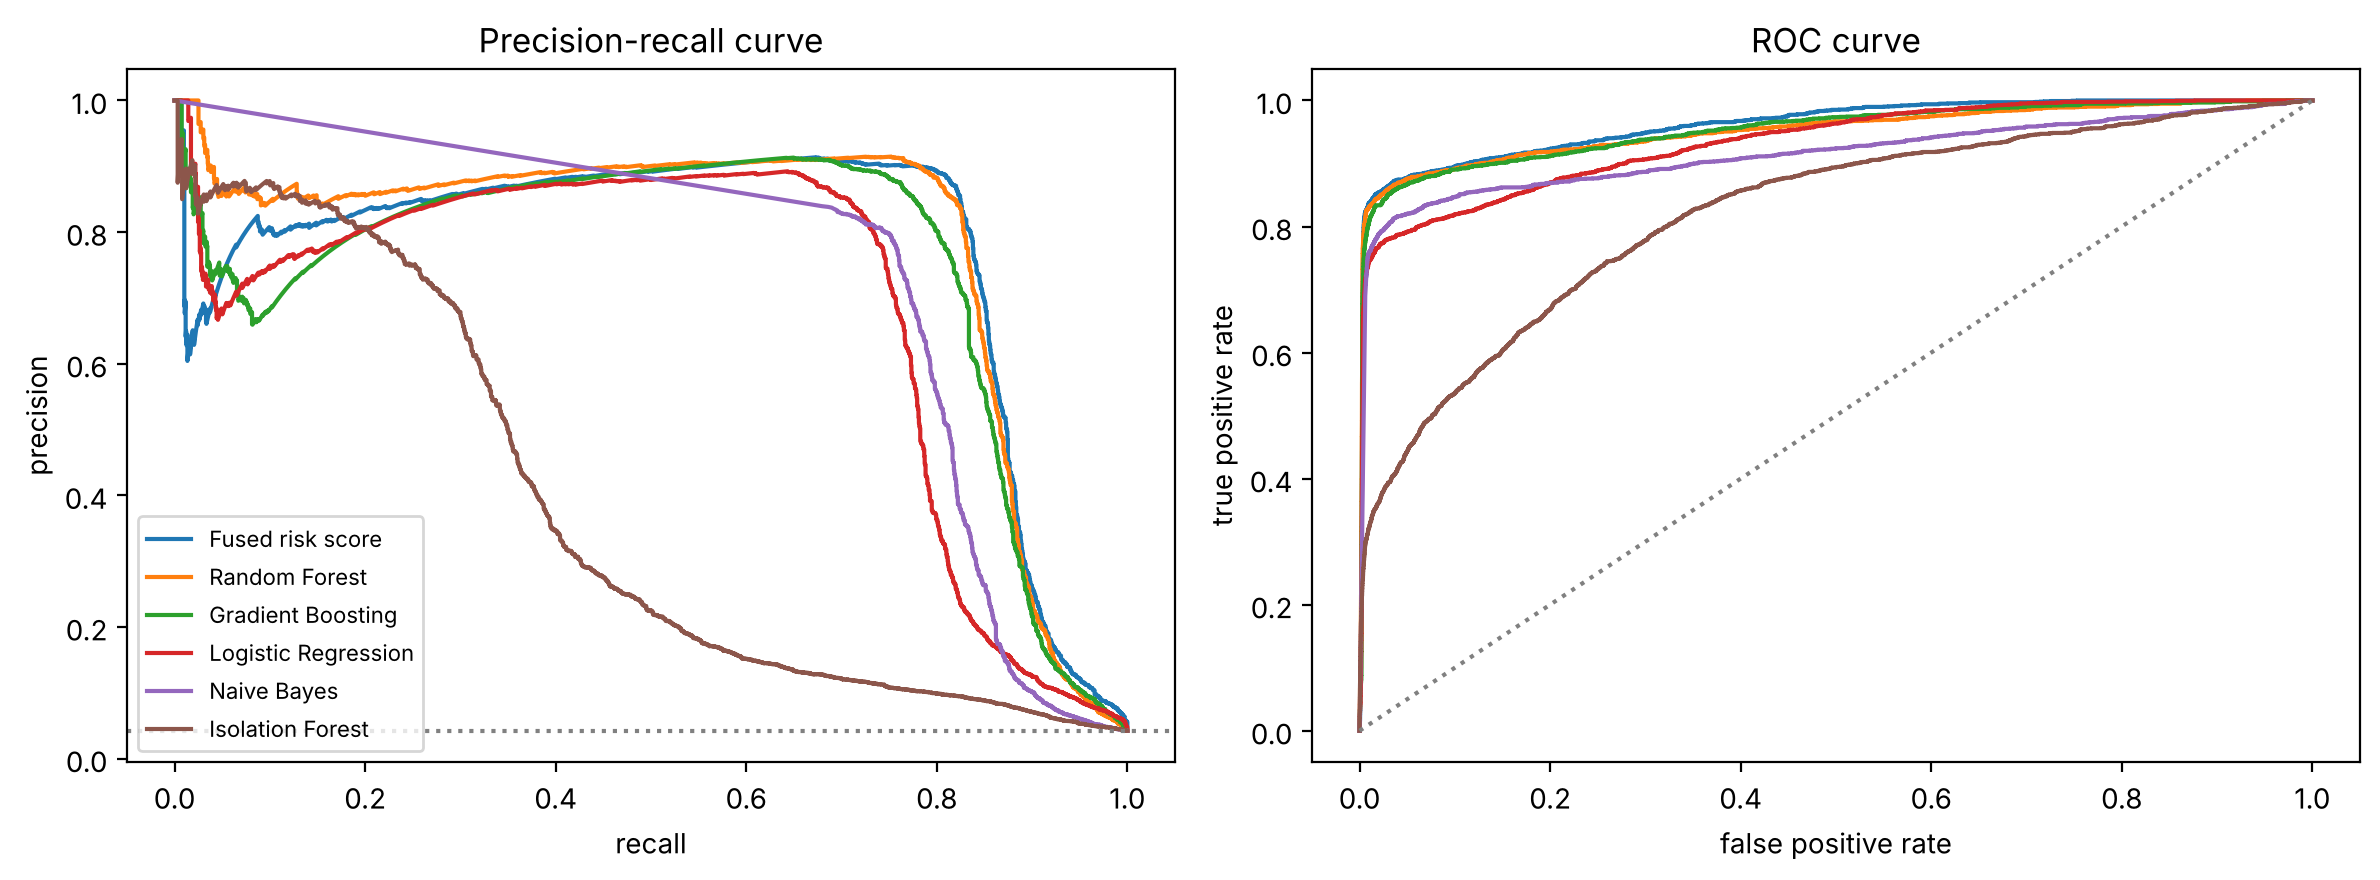

In [30]:
from sklearn.metrics import roc_curve
show = ["Fused risk score", "Random Forest", "Gradient Boosting", "Logistic Regression", "Naive Bayes", "Isolation Forest"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for name in show:
    p, r, _ = precision_recall_curve(y_te, scores[name][1]); ax[0].plot(r, p, label=name)
    fpr, tpr, _ = roc_curve(y_te, scores[name][1]); ax[1].plot(fpr, tpr, label=name)
ax[0].axhline(y_te.mean(), color="grey", ls=":"); ax[0].set(xlabel="recall", ylabel="precision", title="Precision-recall curve")
ax[1].plot([0, 1], [0, 1], color="grey", ls=":"); ax[1].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC curve")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

### 6.3 Confusion matrix of the best model
Rows = what really happened, columns = what the model said.

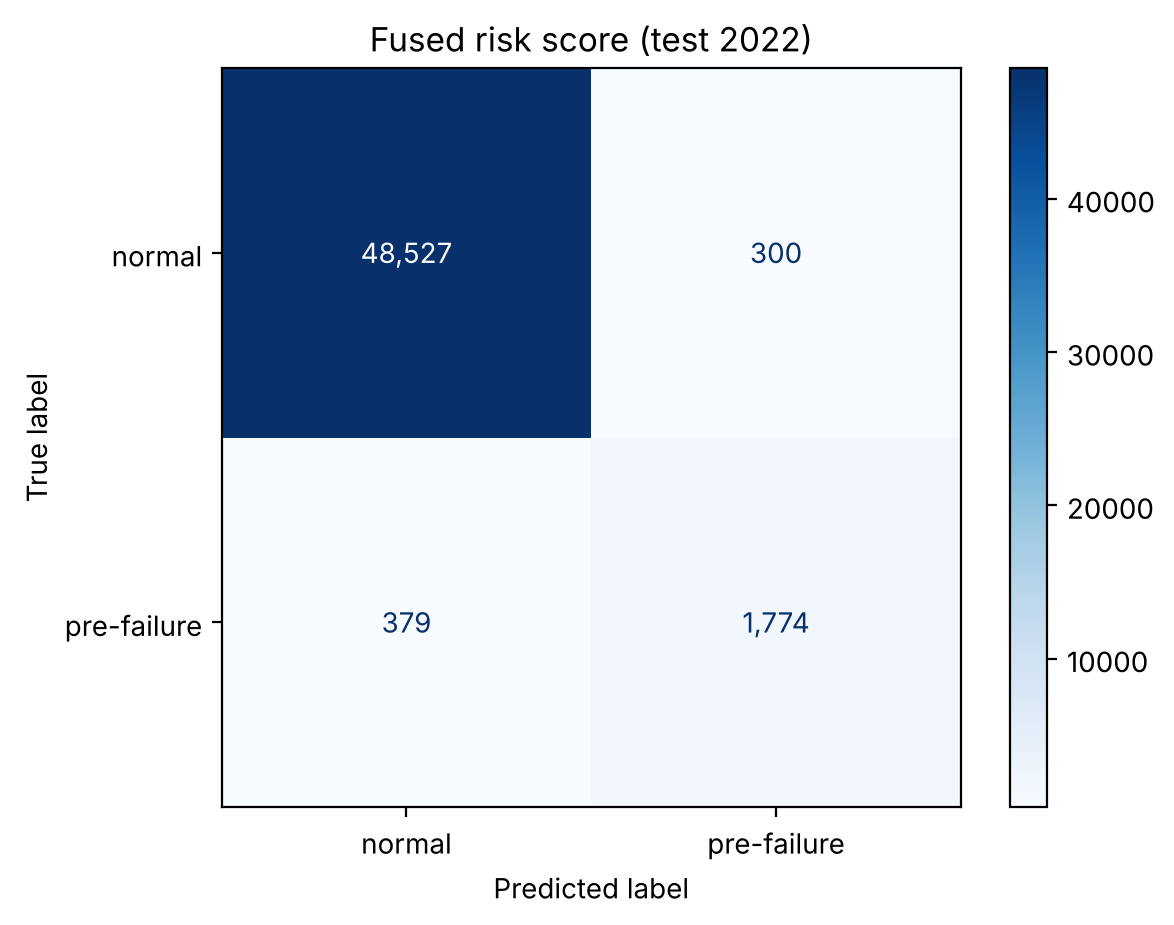

In [31]:
from sklearn.metrics import ConfusionMatrixDisplay
best = comparison.drop(index=["Isolation Forest"]).f1.idxmax()
alert_best = scores[best][1] >= thresholds[best]
ConfusionMatrixDisplay.from_predictions(y_te, alert_best, display_labels=["normal", "pre-failure"], cmap="Blues", values_format=",d")
plt.title(f"{best} (test 2022)"); plt.show()

### 6.4 Which sensors matter most?
Random Forest importance, added up per sensor.

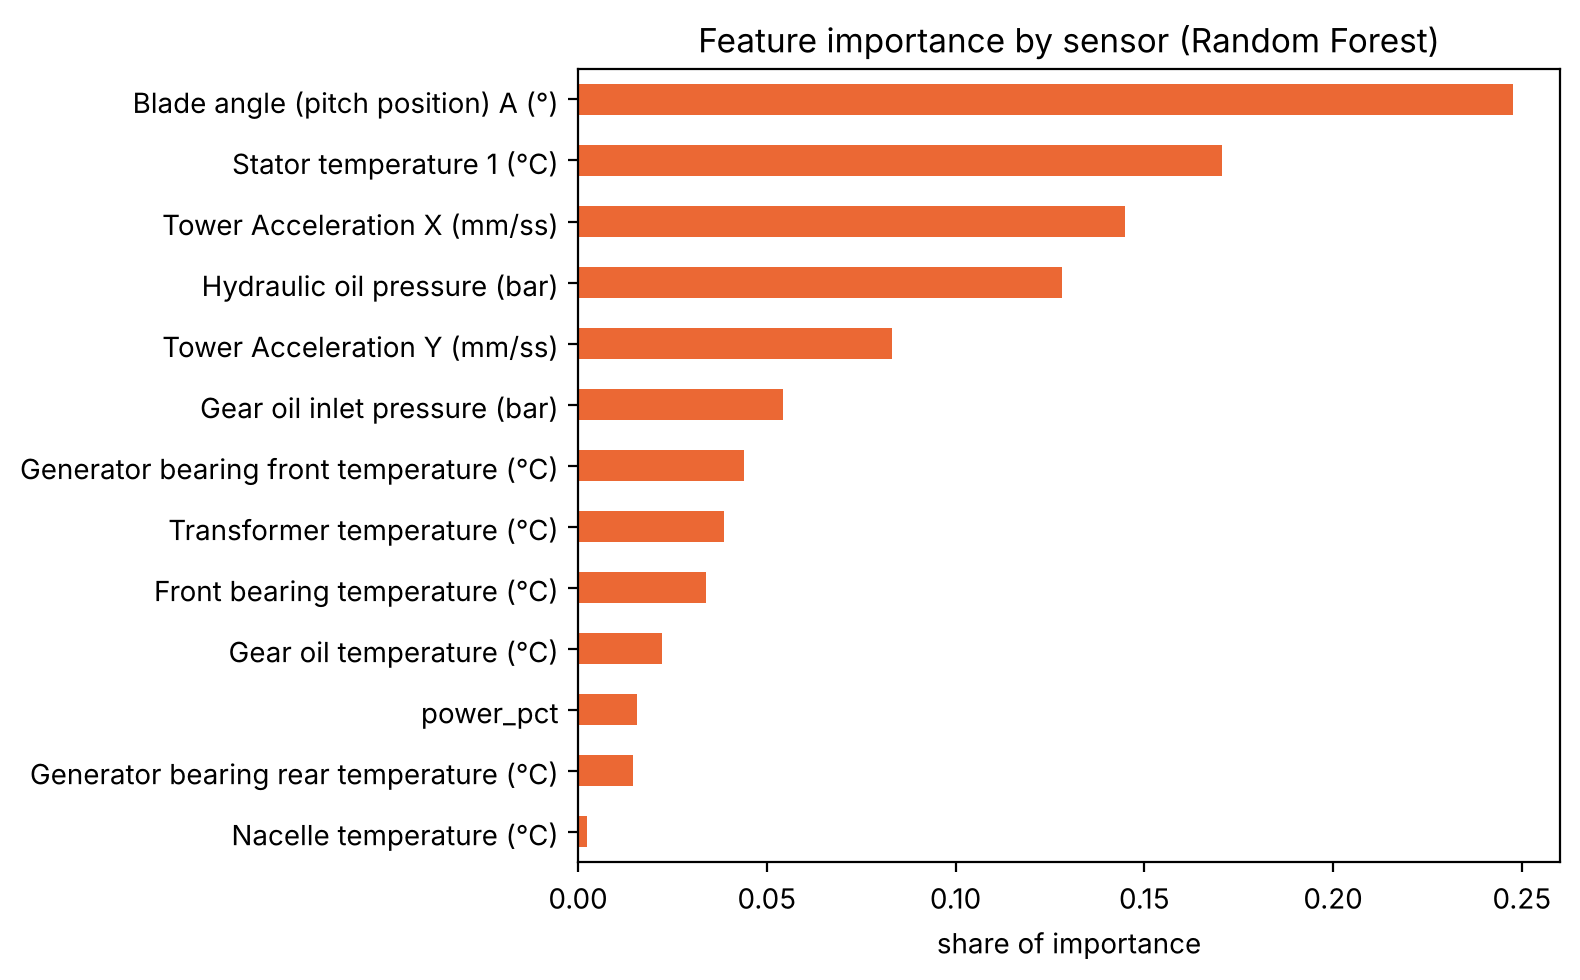

In [32]:
importance = pd.Series(rf.feature_importances_, index=X.columns)
by_sensor = importance.groupby([c.split("__")[0] for c in X.columns]).sum().sort_values()
by_sensor.plot.barh(figsize=(8, 5), color="#eb6834")
plt.xlabel("share of importance"); plt.title("Feature importance by sensor (Random Forest)"); plt.tight_layout(); plt.show()

### 6.5 Failure-level view: did we warn before each failure?
Row-level scores treat every hour alone. In practice we care whether a **failure got a warning** in time, and how many **false alarms** we raise.

In [33]:
def failure_level(name):
    alert = scores[name][1] >= thresholds[name]
    m = meta[te].reset_index(drop=True)
    caught, lead = [], []
    for ep, rows in m[m.label == 1].groupby("episode"):
        hit = alert[rows.index.to_numpy()]
        caught.append(hit.any())
        if hit.any():
            lead.append(rows["days_to_failure"].to_numpy()[hit].max())          # warning time before the failure
    normal = m[(m.label == 0)].assign(alert=alert[m.label == 0]).query("alert").sort_values(["turbine", "Date and time"])
    new_event = normal.groupby("turbine")["Date and time"].diff().isna() | (normal.groupby("turbine")["Date and time"].diff() > pd.Timedelta(hours=24))
    return dict(model=name, failures=len(caught), warned=int(sum(caught)), warned_pct=round(100 * np.mean(caught)),
                median_warning_days=round(float(np.median(lead)), 1), false_alarms_per_turbine_year=round(new_event.sum() / m.turbine.nunique(), 1))

pd.DataFrame([failure_level(n) for n in ["Fused risk score", "Random Forest", "Gradient Boosting", "Logistic Regression"]]).set_index("model")

,failures,warned,warned_pct,median_warning_days,false_alarms_per_turbine_year
model,,,,,
Fused risk score,13,13,100,6.5,7.2
Random Forest,13,13,100,6.5,5.8
Gradient Boosting,13,13,100,6.3,5.5
Logistic Regression,13,12,92,6.4,6.2


### 6.6 Confidence intervals (bootstrap)
The test year has few failures, so one number can be lucky. We re-draw the test set many times (in blocks of one turbine-week, because neighbouring hours are almost identical) and look at the spread.

In [34]:
def bootstrap_ci(name, n_boot=300):
    alert = scores[name][1] >= thresholds[name]
    m = meta[te].reset_index(drop=True)
    block = m.turbine.astype(str) + "_" + m["Date and time"].dt.isocalendar().week.astype(str)
    counts = pd.DataFrame({"tp": alert & (y_te == 1), "fp": alert & (y_te == 0), "fn": ~alert & (y_te == 1)}).groupby(block.to_numpy()).sum()
    rng, out = np.random.RandomState(0), []
    for _ in range(n_boot):
        c = counts.iloc[rng.randint(0, len(counts), len(counts))].sum()
        p, r = c.tp / max(c.tp + c.fp, 1), c.tp / max(c.tp + c.fn, 1)
        out.append((p, r, 2 * p * r / max(p + r, 1e-9)))
    lo, hi = np.percentile(out, 2.5, axis=0), np.percentile(out, 97.5, axis=0)
    return {"model": name, **{k: f"[{l:.2f} - {h:.2f}]" for k, l, h in zip(["precision 95% CI", "recall 95% CI", "F1 95% CI"], lo, hi)}}

pd.DataFrame([bootstrap_ci(n) for n in ["Fused risk score", "Random Forest", "Gradient Boosting", "Logistic Regression"]]).set_index("model")

,precision 95% CI,recall 95% CI,F1 95% CI
model,,,
Fused risk score,[0.70 - 0.96],[0.70 - 0.93],[0.73 - 0.91]
Random Forest,[0.71 - 0.96],[0.68 - 0.91],[0.72 - 0.91]
Gradient Boosting,[0.69 - 0.96],[0.63 - 0.88],[0.71 - 0.89]
Logistic Regression,[0.69 - 0.96],[0.53 - 0.84],[0.65 - 0.86]


### 6.7 Stratified cross-validation (training years)
5 folds. Hours from the same 2-week block always stay in the same fold, so a failure cannot leak between training and checking.

In [35]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.base import clone

groups = (meta[tr].turbine.astype(str) + "_" + (meta[tr]["Date and time"].dt.dayofyear // 14).astype(str) + "_" + meta[tr]["Date and time"].dt.year.astype(str)).to_numpy()
cv_rows = []
for name, model in [("Logistic Regression", lr), ("Naive Bayes", nb), ("Random Forest", rf), ("Gradient Boosting", gb)]:
    aps, aucs = [], []
    for fit_idx, chk_idx in StratifiedGroupKFold(5, shuffle=True, random_state=0).split(Z_tr, y_tr, groups):
        m = clone(model)
        if name == "Random Forest": m.set_params(n_estimators=50, max_depth=10)       # smaller forest only inside the CV loop, to keep it fast
        m.fit(Z_tr[fit_idx], y_tr[fit_idx]); p = m.predict_proba(Z_tr[chk_idx])[:, 1]
        aps.append(average_precision_score(y_tr[chk_idx], p)); aucs.append(roc_auc_score(y_tr[chk_idx], p))
    cv_rows.append({"model": name, "PR-AUC mean": np.mean(aps), "PR-AUC std": np.std(aps), "ROC-AUC mean": np.mean(aucs), "ROC-AUC std": np.std(aucs)})
pd.DataFrame(cv_rows).set_index("model").round(3)

,PR-AUC mean,PR-AUC std,ROC-AUC mean,ROC-AUC std
model,,,,
Logistic Regression,0.666,0.079,0.863,0.040
Naive Bayes,0.755,0.045,0.929,0.028
Random Forest,0.830,0.049,0.947,0.027
Gradient Boosting,0.815,0.063,0.925,0.039


## 7. Extras
### 7.1 Remaining useful life (RUL): how many days until the failure?
We train only on pre-failure hours and predict `days_to_failure` (0 to 7). We compare Linear, Ridge and Lasso regression with a baseline that always guesses the average.

In [36]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, r2_score

pre_tr, pre_te = tr & (y == 1), te & (y == 1)
days = kel["days_to_failure"].to_numpy()
rul_models = {}
rul_rows = [{"model": "Always guess the average", "MAE (days)": mean_absolute_error(days[pre_te], np.full(pre_te.sum(), days[pre_tr].mean())), "R2": 0.0}]
for name, reg in [("Linear", LinearRegression()), ("Ridge", Ridge(alpha=100)), ("Lasso", Lasso(alpha=0.01))]:
    reg.fit(Z[pre_tr], days[pre_tr]); pred = np.clip(reg.predict(Z[pre_te]), 0, PRE_DAYS)
    rul_models[name] = reg
    rul_rows.append({"model": name, "MAE (days)": mean_absolute_error(days[pre_te], pred), "R2": r2_score(days[pre_te], pred)})
rul = pd.DataFrame(rul_rows).set_index("model").round(2); rul.to_csv(f"{OUT}/rul_results.csv"); rul

,MAE (days),R2
model,,
Always guess the average,1.75,0.00
Linear,1.51,0.21
Ridge,1.51,0.21
Lasso,1.52,0.21


### 7.2 Cross-farm test: train on Kelmarsh, test on Penmanshiel (no retraining)
A model is only useful if it works on a farm it has never seen. Rules: use only sensors both farms have, and do not tune anything on Penmanshiel (the alert threshold comes from Kelmarsh 2021).

In [37]:
pen, pen_status = load_farm("Penmanshiel")
pen_failures = find_failures(pen_status)
pen = add_labels(pen, pen_failures, pen_status)
pen["power_mean_6h"] = pen.groupby("turbine")["Power (kW)"].transform(lambda s: s.rolling(6, min_periods=3).mean())
common = [s for s in SENSORS if s in pen.columns and pen[s].notna().any()]
print(f"Penmanshiel: {len(pen_failures)} failures, {pen.turbine.nunique()} turbines. Sensors in both farms: {len(common)} of {len(SENSORS)}")
print("Missing in Penmanshiel:", [s for s in SENSORS if s not in common])

Penmanshiel: 128 failures, 14 turbines. Sensors in both farms: 10 of 12
Missing in Penmanshiel: ['Gear oil inlet pressure (bar)', 'Hydraulic oil pressure (bar)']


Penmanshiel residuals use the **Kelmarsh** normal-behaviour models; each turbine's offset comes from its own first 25 % of time.

In [38]:
pen_res = get_residuals(pen, normal_model, common)
first_quarter = pen.groupby("turbine")["Date and time"].transform(lambda t: t < t.min() + 0.25 * (t.max() - t.min()))
pen_res = pen_res - pen_res[first_quarter & (pen.label == 0)].groupby(pen.turbine).median().reindex(pen.turbine).to_numpy()
Xp = make_features(pen_res, pen)
cols = [c for c in X.columns if c.split("__")[0] in common or c == "power_pct"]
print("Common features:", len(cols))

Common features: 31


Compare two ways of scaling the Penmanshiel features: with Kelmarsh statistics, or with its own first 25 % of data (no labels needed).

In [39]:
idx = [list(X.columns).index(c) for c in cols]
gb_common = HistGradientBoostingClassifier(max_iter=200, max_depth=4, learning_rate=0.1, class_weight="balanced", random_state=0).fit(Z_tr[:, idx], y_tr)
thr = best_threshold(y_va, gb_common.predict_proba(Z_va[:, idx])[:, 1])

use_p = ~pen.skip.to_numpy(); y_p = pen.label.to_numpy()[use_p]
own = first_quarter.to_numpy() & use_p & (pen.label == 0).to_numpy()
mean_own, std_own = Xp.loc[own, cols].mean().to_numpy(), Xp.loc[own, cols].std().to_numpy() + 1e-6
versions = {"Penmanshiel, scaled with its own data": (Xp[cols].to_numpy() - mean_own) / std_own,
            "Penmanshiel, scaled with Kelmarsh data": (Xp[cols].to_numpy() - scaler.mean_[idx]) / scaler.scale_[idx]}
rows = []
p_k = gb_common.predict_proba(Z_te[:, idx])[:, 1]
rows.append(dict(data="Kelmarsh test 2022 (same farm)", pr_auc=average_precision_score(y_te, p_k), roc_auc=roc_auc_score(y_te, p_k),
                 precision=precision_score(y_te, p_k >= thr), recall=recall_score(y_te, p_k >= thr)))
for name, Zp in versions.items():
    p = gb_common.predict_proba(np.clip(Zp, -8, 8)[use_p])[:, 1]
    rows.append(dict(data=name, pr_auc=average_precision_score(y_p, p), roc_auc=roc_auc_score(y_p, p),
                     precision=precision_score(y_p, p >= thr), recall=recall_score(y_p, p >= thr)))
cross_farm = pd.DataFrame(rows).set_index("data").round(3); cross_farm.to_csv(f"{OUT}/cross_farm_results.csv")
print(f"No-skill PR-AUC on Penmanshiel is about {y_p.mean():.3f}")
cross_farm

No-skill PR-AUC on Penmanshiel is about 0.044


,pr_auc,roc_auc,precision,recall
data,,,,
Kelmarsh test 2022 (same farm),0.612,0.884,0.836,0.612
"Penmanshiel, scaled with its own data",0.589,0.828,0.546,0.584
"Penmanshiel, scaled with Kelmarsh data",0.151,0.727,0.084,0.627


## 8. Summary and saving the results

In [40]:
summary = comparison[["precision", "recall", "f1", "pr_auc", "roc_auc"]].head(5)
fl = pd.DataFrame([failure_level("Fused risk score")]).set_index("model")
summary.to_csv(f"{OUT}/summary_top_models.csv"); fl.to_csv(f"{OUT}/failure_level_fused.csv")
print("Saved to", OUT, ":", sorted(os.listdir(OUT)))
summary

Saved to /home/claude/simple/out2 : ['cross_farm_results.csv', 'failure_level_fused.csv', 'model_comparison_test.csv', 'rul_results.csv', 'summary_top_models.csv']


,precision,recall,f1,pr_auc,roc_auc
model,,,,,
Random Forest,0.865,0.808,0.836,0.785,0.952
ANN (64-32),0.872,0.769,0.818,0.777,0.941
Fused risk score,0.855,0.824,0.839,0.767,0.962
Gradient Boosting,0.855,0.773,0.812,0.744,0.953
SVM (linear),0.871,0.669,0.757,0.737,0.942


## 9. Export for the dashboard
The Streamlit app (folder `windguard_app/`) reads the files made here, so the **notebook and the dashboard always show the same numbers**. Every cell builds one piece; the last cell saves everything into `OUT/dashboard_export`.

### 9.1 One probability per model
The SVM and the Isolation Forest give scores, not probabilities. Platt scaling (a small logistic regression fitted on the validation year) turns a score into a 0-1 number, so every model can be shown the same way.

In [41]:
def as_probability(name):
    cal = LogisticRegression(C=1e4).fit(scores[name][0].reshape(-1, 1), y_va)
    return cal, [cal.predict_proba(s.reshape(-1, 1))[:, 1] for s in scores[name]]

svm_cal, svm_prob = as_probability("SVM (linear)")
prob_columns = {                 # column name in the dashboard table -> (validation, test) probabilities
    "risk": scores["Fused risk score"], "p_random_forest": scores["Random Forest"], "p_gradient_boosting": scores["Gradient Boosting"],
    "p_ann": scores["ANN (64-32)"], "p_logistic": scores["Logistic Regression"], "p_svm": tuple(svm_prob), "p_bayes": scores["Naive Bayes"]}
pd.DataFrame({k: v[1] for k, v in prob_columns.items()}).describe().loc[["mean", "50%", "max"]].round(3)

,risk,p_random_forest,p_gradient_boosting,p_ann,p_logistic,p_svm,p_bayes
mean,0.190,0.166,0.127,0.068,0.276,0.048,0.059
50%,0.152,0.116,0.065,0.000,0.234,0.012,0.000
max,1.000,1.000,1.000,1.000,1.000,1.000,1.000


### 9.2 Risk bands
**Watch** = lower threshold that catches more failures (best F2 on 2021). **High** = balanced threshold (best F1 on 2021). Both are fixed on the validation year and then applied to 2022.

In [42]:
def threshold_for(y_true, score, beta):
    p, r, t = precision_recall_curve(y_true, score)
    fb = (1 + beta ** 2) * p[:-1] * r[:-1] / (beta ** 2 * p[:-1] + r[:-1] + 1e-9)
    return t[np.argmax(fb)]

watch_thr, high_thr = threshold_for(y_va, prob_columns["risk"][0], 2), threshold_for(y_va, prob_columns["risk"][0], 1)
if high_thr < watch_thr: watch_thr, high_thr = high_thr, watch_thr          # keep the bands ordered
pd.DataFrame({"threshold": [watch_thr, high_thr]}, index=["Watch (F2)", "High (F1)"]).round(3)

,threshold
Watch (F2),0.448
High (F1),0.547


### 9.3 The hourly table (validation + test years)
One row per turbine-hour: the label, every model's probability, the risk band, the main sensors, the three sensors that deviate most (for flagged hours) and a days-to-failure estimate (for flagged hours).

In [43]:
sensor_cols = ["Wind speed (m/s)", "Power (kW)", "Nacelle ambient temperature (°C)", "Gear oil temperature (°C)", "Front bearing temperature (°C)",
               "Generator bearing front temperature (°C)", "Stator temperature 1 (°C)", "Gear oil inlet pressure (bar)", "Hydraulic oil pressure (bar)"]
six_h = [list(X.columns).index(f"{s}__6h") for s in SENSORS]                # 6-hour residual of every sensor (in standard deviations)
rul_model_name = "Lasso"

def hourly_rows(mask, split_name, k):
    t = pd.DataFrame({"turbine": kel.turbine[mask].to_numpy(), "year": year[mask].to_numpy(), "Date and time": kel["Date and time"][mask].to_numpy(),
                      "target_any_fault": y[mask].astype("int8"), "episode_id": kel.episode[mask].to_numpy().astype("int32"), "split": split_name})
    for col, pair in prob_columns.items(): t[col] = pair[k].astype("float32")
    t["anomaly_score"] = scores["Isolation Forest"][k].astype("float32")
    for s in sensor_cols: t[s] = kel.loc[mask, s].to_numpy().astype("float32")
    t["band"] = np.where(t.risk >= high_thr, "High", np.where(t.risk >= watch_thr, "Watch", "Low"))
    flag = (t.band != "Low").to_numpy()
    Zs = Z[mask]
    t["rul_days_est"] = np.nan
    t.loc[flag, "rul_days_est"] = np.clip(rul_models[rul_model_name].predict(Zs[flag]), 0, PRE_DAYS)
    zz = Zs[flag][:, six_h]; top3 = np.argsort(-np.abs(zz), axis=1)[:, :3]
    t["top_drivers"] = ""
    t.loc[flag, "top_drivers"] = ["; ".join(f"{SENSORS[j]} {zz[i, j]:+.1f}σ" for j in top3[i]) for i in range(len(zz))]
    return t

replay = pd.concat([hourly_rows(va, "val", 0), hourly_rows(te, "test", 1)]).sort_values(["turbine", "Date and time"]).reset_index(drop=True)
replay.groupby(["split", "band"]).size().unstack(fill_value=0)

band,High,Low,Watch
split,,,
test,2074,48658,248
val,2251,48725,270


### 9.4 Failure list
Every failure with the time it happened and whether the fused risk reached Watch / High at least once in the 7 days before it (2021 and 2022 only).

In [44]:
episodes = kel_failures.rename_axis("episode_id").reset_index()
episodes["year"] = episodes.t_fail.dt.year
for band, thr in [("watch", watch_thr), ("high", high_thr)]:
    hit = replay[(replay.target_any_fault == 1) & (replay.risk >= thr)].episode_id.unique()
    episodes[f"warned_{band}"] = np.where(episodes.year.isin([VAL_YEAR, TEST_YEAR]), episodes.episode_id.isin(hit).astype(float), np.nan)
episodes[episodes.year == TEST_YEAR][["turbine", "message", "t_fail", "warned_watch", "warned_high"]]

,turbine,message,t_fail,warned_watch,warned_high
15,1,Pitch system fault,2022-03-28 10:00:12,1.0,1.0
16,1,Converter overtemperature fault,2022-07-06 20:20:55,1.0,1.0
17,1,Converter overtemperature fault,2022-09-17 17:52:46,1.0,1.0
29,2,Generator bearing overtemperature,2022-01-25 21:33:01,1.0,1.0
30,2,Pitch system fault,2022-08-10 12:56:32,1.0,1.0
41,3,Pitch system fault,2022-03-17 14:29:17,1.0,1.0
42,3,Yaw system fault,2022-07-27 19:01:50,1.0,1.0
54,4,Hydraulic pressure low,2022-08-17 20:30:33,1.0,1.0
55,4,Gearbox oil temperature high,2022-09-20 12:27:49,1.0,1.0
70,5,Yaw system fault,2022-03-22 03:24:27,1.0,1.0


### 9.5 Model comparison table
Same numbers as section 6.1 plus the failure-level view (6.5) for every model.

In [45]:
family = {"Logistic Regression": "Linear", "SVM (linear)": "Linear", "Naive Bayes": "Bayesian", "Random Forest": "Tree ensemble", "Gradient Boosting": "Tree ensemble",
          "ANN (64-32)": "Neural network", "Isolation Forest": "Anomaly (unsupervised)", "Fused risk score": "Fusion"}
column_of = {"Fused risk score": "risk", "Random Forest": "p_random_forest", "Gradient Boosting": "p_gradient_boosting", "ANN (64-32)": "p_ann",
             "Logistic Regression": "p_logistic", "SVM (linear)": "p_svm", "Naive Bayes": "p_bayes"}
rows = []
for r in results:
    name = r["model"]; alert = scores[name][1] >= thresholds[name]; fl = failure_level(name)
    shown_thr = svm_cal.predict_proba([[thresholds[name]]])[0, 1] if name == "SVM (linear)" else thresholds[name]       # SVM threshold on the probability scale
    rows.append({**r, "family": family[name], "column": column_of.get(name, ""), "threshold": shown_thr,
                 "tp": int((alert & (y_te == 1)).sum()), "fp": int((alert & (y_te == 0)).sum()), "fn": int((~alert & (y_te == 1)).sum()), "tn": int((~alert & (y_te == 0)).sum()),
                 "episode_recall": fl["warned"] / fl["failures"], "median_lead_days": fl["median_warning_days"], "fa_per_turbine_year": fl["false_alarms_per_turbine_year"]})
model_table = pd.DataFrame(rows)
model_table[["model", "family", "pr_auc", "roc_auc", "precision", "recall", "f1", "episode_recall", "median_lead_days", "fa_per_turbine_year"]].round(3).set_index("model")

,family,pr_auc,roc_auc,precision,recall,f1,episode_recall,median_lead_days,fa_per_turbine_year
model,,,,,,,,,
Logistic Regression,Linear,0.687,0.934,0.853,0.699,0.768,0.923,6.4,6.2
SVM (linear),Linear,0.737,0.942,0.871,0.669,0.757,0.923,6.3,4.2
Naive Bayes,Bayesian,0.697,0.916,0.790,0.753,0.771,1.000,6.2,15.3
Random Forest,Tree ensemble,0.785,0.952,0.865,0.808,0.836,1.000,6.5,5.8
Gradient Boosting,Tree ensemble,0.744,0.953,0.855,0.773,0.812,1.000,6.3,5.5
ANN (64-32),Neural network,0.777,0.941,0.872,0.769,0.818,1.000,6.6,6.8
Isolation Forest,Anomaly (unsupervised),0.381,0.822,0.379,0.388,0.383,0.846,5.6,48.2
Fused risk score,Fusion,0.767,0.962,0.855,0.824,0.839,1.000,6.5,7.2


### 9.6 Which sensors matter? (permutation importance)
For each sensor we scramble **all** its features together on the validation year and see how much the Random Forest's PR-AUC drops. A big drop = the model relies on that sensor.

In [46]:
sensor_of_feature = np.array([("operating context (power)" if c == "power_pct" else c.split("__")[0]) for c in X.columns])
sample = np.random.RandomState(0).choice(len(Z_va), min(20000, len(Z_va)), replace=False)
Zs, ys = Z_va[sample], y_va[sample]
base_ap = average_precision_score(ys, rf.predict_proba(Zs)[:, 1])
drops = {}
for g in pd.unique(sensor_of_feature):
    cols_g = np.flatnonzero(sensor_of_feature == g); loss = []
    for rep in range(2):
        Zp = Zs.copy(); Zp[:, cols_g] = Zs[np.random.RandomState(rep).permutation(len(Zs))][:, cols_g]
        loss.append(base_ap - average_precision_score(ys, rf.predict_proba(Zp)[:, 1]))
    drops[g] = np.mean(loss)
rf_share = pd.Series(rf.feature_importances_, index=sensor_of_feature).groupby(level=0).sum()
importance_table = pd.DataFrame({"sensor_group": list(drops), "perm_drop_pr_auc": list(drops.values())}).assign(rf_gini_share=lambda d: d.sensor_group.map(rf_share))
importance_table = importance_table.sort_values("perm_drop_pr_auc", ascending=False).reset_index(drop=True)
importance_table.round(3).head(8)

,sensor_group,perm_drop_pr_auc,rf_gini_share
0,Hydraulic oil pressure (bar),0.365,0.128
1,Blade angle (pitch position) A (°),0.222,0.248
2,Stator temperature 1 (°C),0.168,0.170
3,Tower Acceleration X (mm/ss),0.052,0.145
4,Gear oil inlet pressure (bar),0.020,0.054
5,operating context (power),0.019,0.016
6,Generator bearing front temperature (°C),0.013,0.044
7,Transformer temperature (°C),0.010,0.039


### 9.7 Bootstrap confidence intervals (with PR-AUC and ROC-AUC)
Same idea as 6.6: re-draw whole turbine-weeks 150 times, then read the 95% range. The test year has few failures, so the ranges are wide.

In [47]:
def ci_text(values, point):
    lo, hi = np.percentile(values, [2.5, 97.5]); return f"{point:.3f} [{lo:.3f}, {hi:.3f}]"

m_te = meta[te].reset_index(drop=True)
block_id = (m_te.turbine.astype(str) + "_" + m_te["Date and time"].dt.isocalendar().week.astype(str)).to_numpy()
block_rows = [np.flatnonzero(block_id == b) for b in pd.unique(block_id)]
ci_rows = []
for name in ["Fused risk score", "Random Forest", "Gradient Boosting", "Logistic Regression", "Naive Bayes"]:
    s, alert, draws = scores[name][1], scores[name][1] >= thresholds[name], {k: [] for k in ["precision", "recall", "f1", "pr_auc", "roc_auc"]}
    rng = np.random.RandomState(0)
    for _ in range(150):
        idx = np.concatenate([block_rows[i] for i in rng.randint(0, len(block_rows), len(block_rows))])
        if y_te[idx].sum() == 0: continue
        p, r_ = precision_score(y_te[idx], alert[idx], zero_division=0), recall_score(y_te[idx], alert[idx])
        draws["precision"].append(p); draws["recall"].append(r_); draws["f1"].append(2 * p * r_ / max(p + r_, 1e-9))
        draws["pr_auc"].append(average_precision_score(y_te[idx], s[idx])); draws["roc_auc"].append(roc_auc_score(y_te[idx], s[idx]))
    row = results_df = comparison.loc[name]
    ci_rows.append({"model": name, **{k: ci_text(v, row[k]) for k, v in draws.items()}})
ci_table = pd.DataFrame(ci_rows)
ci_table.set_index("model")

,precision,recall,f1,pr_auc,roc_auc
model,,,,,
Fused risk score,"0.855 [0.717, 0.956]","0.824 [0.713, 0.933]","0.839 [0.745, 0.908]","0.767 [0.600, 0.922]","0.962 [0.937, 0.984]"
Random Forest,"0.865 [0.725, 0.961]","0.808 [0.698, 0.924]","0.836 [0.742, 0.907]","0.785 [0.621, 0.918]","0.952 [0.921, 0.981]"
Gradient Boosting,"0.855 [0.711, 0.960]","0.773 [0.665, 0.896]","0.812 [0.722, 0.888]","0.744 [0.555, 0.906]","0.953 [0.928, 0.977]"
Logistic Regression,"0.853 [0.706, 0.955]","0.699 [0.545, 0.862]","0.768 [0.622, 0.873]","0.687 [0.464, 0.874]","0.934 [0.891, 0.976]"
Naive Bayes,"0.790 [0.628, 0.903]","0.753 [0.630, 0.880]","0.771 [0.668, 0.854]","0.697 [0.550, 0.836]","0.916 [0.853, 0.973]"


### 9.8 Cross-farm and cross-validation tables in the dashboard format

In [48]:
farm_names = {"Kelmarsh test 2022 (same farm)": ("Kelmarsh 2022 (in-farm)", "Kelmarsh"),
              "Penmanshiel, scaled with its own data": ("Penmanshiel (cross-farm)", "per-farm (target farm's own early data)"),
              "Penmanshiel, scaled with Kelmarsh data": ("Penmanshiel (cross-farm)", "Kelmarsh statistics (no adaptation)")}
cross_export = cross_farm.reset_index().rename(columns={"data": "key"})
cross_export["farm"] = cross_export.key.map(lambda k: farm_names[k][0]); cross_export["normalisation"] = cross_export.key.map(lambda k: farm_names[k][1])
cross_export.insert(0, "model", "Gradient Boosting"); cross_export = cross_export.drop(columns="key")

cv_table = pd.DataFrame(cv_rows).rename(columns={"PR-AUC mean": "pr_auc_mean", "PR-AUC std": "pr_auc_sd", "ROC-AUC mean": "roc_auc_mean", "ROC-AUC std": "roc_auc_sd"})
cross_export.round(3)

,model,pr_auc,roc_auc,precision,recall,farm,normalisation
0,Gradient Boosting,0.612,0.884,0.836,0.612,Kelmarsh 2022 (in-farm),Kelmarsh
1,Gradient Boosting,0.589,0.828,0.546,0.584,Penmanshiel (cross-farm),per-farm (target farm's own early data)
2,Gradient Boosting,0.151,0.727,0.084,0.627,Penmanshiel (cross-farm),Kelmarsh statistics (no adaptation)


### 9.9 Which kinds of fault does the second farm still catch?
For each Penmanshiel failure kind: the median percentile rank of the risk score in the 7 hours-days before the failure, among all Penmanshiel hours (1.0 = the highest risk the farm ever shows).

In [49]:
from scipy.stats import rankdata
Zp_own = np.clip(versions["Penmanshiel, scaled with its own data"], -8, 8)[use_p]
p_own = gb_common.predict_proba(Zp_own)[:, 1]
percentile = rankdata(p_own) / len(p_own)
pen_meta = pen[use_p].reset_index(drop=True)
kind_words = [("gearbox", "gearbox"), ("generator bearing", "genbear"), ("main bearing", "mainbear"), ("hydraulic", "hydraulic"), ("pitch", "pitch"),
              ("converter", "converter"), ("stator", "stator"), ("yaw", "yaw")]
def fault_kind(msg):
    m = str(msg).lower(); return next((k for w, k in kind_words if w in m), "other")
pen_failures["kind"] = pen_failures.message.map(fault_kind)
pre = pen_meta[pen_meta.label == 1].assign(pct=percentile[pen_meta.label.to_numpy() == 1])
per_failure = pre.groupby("episode").pct.median()
fault_kind_table = (pen_failures.assign(pct=per_failure.reindex(pen_failures.index)).dropna(subset=["pct"]).groupby("kind")
                    .agg(n=("pct", "size"), median_percentile=("pct", "median")).round(2).reset_index())
fault_kind_table

,kind,n,median_percentile
0,converter,9,0.98
1,gearbox,20,0.99
2,genbear,23,0.99
3,hydraulic,10,0.42
4,mainbear,13,0.98
5,pitch,28,0.77
6,stator,13,0.97
7,yaw,12,0.99


### 9.10 Save everything for the dashboard

In [50]:
EXPORT = OUT + "/dashboard_export"
os.makedirs(EXPORT, exist_ok=True)
replay.to_parquet(f"{EXPORT}/replay_scores_hourly.parquet", index=False)
episodes.to_csv(f"{EXPORT}/episodes.csv", index=False)
model_table.to_csv(f"{EXPORT}/model_comparison_2022.csv", index=False)
importance_table.to_csv(f"{EXPORT}/feature_importance.csv", index=False)
pd.DataFrame({"component": ["Logistic Regression", "Random Forest", "Gradient Boosting"], "weight": [round(1 / 3, 3)] * 3}).to_csv(f"{EXPORT}/fusion_weights.csv", index=False)
ci_table.to_csv(f"{EXPORT}/bootstrap_ci_2022.csv", index=False)
cv_table.to_csv(f"{EXPORT}/cv_summary.csv", index=False)
cross_export.to_csv(f"{EXPORT}/cross_farm_results.csv", index=False)
fault_kind_table.to_csv(f"{EXPORT}/cross_farm_by_fault_kind.csv", index=False)
rul.reset_index().rename(columns={"MAE (days)": "test_mae_days", "R2": "test_r2"}).assign(alpha=lambda d: d.model.map({"Ridge": 100, "Lasso": 0.01})).to_csv(f"{EXPORT}/rul_results.csv", index=False)

import json, datetime
run_info = dict(data_source="synthetic", scenario=SCENARIO, created=datetime.datetime.now().isoformat(timespec="seconds"), train_years=TRAIN_YEARS, val_year=VAL_YEAR,
                test_year=TEST_YEAR, pre_failure_days=PRE_DAYS, n_features=int(X.shape[1]), feature_sensors=list(SENSORS), fused_watch_threshold=float(watch_thr),
                fused_high_threshold=float(high_thr), n_test_rows=int(te.sum()), n_test_episodes=int(len(set(meta[te].episode[y_te == 1]))), rul_model=rul_model_name,
                disclaimer="SIMULATION (scenario: " + SCENARIO + "): synthetic SCADA, results are not performance on real turbines.")
json.dump(run_info, open(f"{EXPORT}/run_info.json", "w"), indent=1)
pd.DataFrame({"file": sorted(os.listdir(EXPORT)), "KB": [round(os.path.getsize(f"{EXPORT}/{f}") / 1024) for f in sorted(os.listdir(EXPORT))]}).set_index("file")

,KB
file,
bootstrap_ci_2022.csv,1
cross_farm_by_fault_kind.csv,0
cross_farm_results.csv,0
cv_summary.csv,0
episodes.csv,7
feature_importance.csv,1
fusion_weights.csv,0
model_comparison_2022.csv,2
replay_scores_hourly.parquet,9284


**Use it in the app:** copy the files from `dashboard_export` into the `data/` folder of `windguard_app`, then start the app (`python run_all.py`). The dashboard now shows exactly the numbers of this notebook.

### How to read the results
* **Everything above is a simulation.** With `SCENARIO = "demo"` the failure signals are strong and start right at the labelled window, so scores are high by design. With `SCENARIO = "realistic"` the same code gives much lower scores (precision and recall around 0.3-0.4).
* **Why the residual features matter:** raw sensor levels depend on weather and season, so models memorise last year's weather; the residual removes that.
* **Few failures** in each test year, so the confidence intervals are wide: do not over-read small differences between the top models.
* **Cross-farm:** ranking ability transfers better than precision; a new farm needs its own calibration.
* To run on the **real Kelmarsh data**, point `DATA_ROOT` at the Drive folder (Greenbyte files with the same column names) and skip the generator cells.

## Appendix: generate the synthetic data inside Colab (only if you do NOT use Google Drive)
Set `USE_DRIVE = False` in the settings cell, then run the two cells below, then run the notebook from the top.

In [51]:
%%writefile windguard_synth.py
#!/usr/bin/env python3
"""
windguard_synth.py  -  Synthetic Kelmarsh-/Penmanshiel-like SCADA + Status-log generator for WindGuard.

WHAT THIS IS
    A physics-informed SIMULATOR. It writes Greenbyte-style CSV folders (same layout, column names and Status-log
    schema the WindGuard notebook already reads), so Members 1-3 code runs on it unchanged:

        <OUT>/Kelmarsh_SCADA_2016_SYN/Turbine_Data_Kelmarsh_1_2016-01-01_-_2017-01-01_SYN.csv
        <OUT>/Kelmarsh_SCADA_2016_SYN/Status_Kelmarsh_1_2016-01-01_-_2017-01-01_SYN.csv
        <OUT>/Penmanshiel_SCADA_2018_SYN/...

WHAT THIS IS NOT
    It is not real turbine data. Healthy behaviour (wind -> power curve, thermal lag, seasonality, per-turbine offsets,
    sensor dropouts, routine stops) follows standard wind-turbine physics. The FAILURE PRECURSORS are an ASSUMPTION:
    how strongly, how early and in which channels a component degradation shows up cannot be learned from the real
    Kelmarsh data (that is exactly the question WindGuard asks). They are therefore explicit, documented parameters
    (see CONFIG / DETECTABILITY) and every result produced on this data must be labelled "simulation".

REALISM DESIGN (what makes scores NOT trivially perfect)
    * Gradual, load-dependent, accelerating degradation ramps that begin days before the fault stop.
    * ~15 % "silent" failures with no SCADA precursor and ~20 % "weak" ones (cf. Carroll et al. 2018: SCADA-only
      detection of roughly 72-75 % of gearbox failures, which is the anchor cited in the project report).
    * Benign look-alike drifts that end in a service visit, not a failure (false-alarm sources).
    * Nuisance fault-like stops that auto-reset (they become provisional "episodes" under the notebook's keyword rule).
    * Per-turbine offsets and gains, cooler-fouling drift, sensor noise, comms gaps, frozen sensors, icing stops.

USAGE
    python windguard_synth.py --out ./WindGuard_Synthetic --seed 7
    python windguard_synth.py --out ./syn --farms kelmarsh --years 2016-2022

    from windguard_synth import generate_farm
    scada_by_turbine, status_all, truth = generate_farm("Kelmarsh", seed=7)
"""
from __future__ import annotations

import argparse
import copy
import json
import os
from dataclasses import dataclass

import numpy as np
import pandas as pd
from scipy.signal import lfilter
from scipy.stats import norm

STEP = pd.Timedelta(minutes=10)
STEPS_PER_DAY = 144

# --------------------------------------------------------------------------------------------------------------------
# Column names (exactly as the notebook expects them). Order matters: after the 8 core channels the notebook ranks the
# remaining channels by coverage and keeps the first ones, so informative channels come first and the least
# informative ones carry the (mild) sensor dropouts below.
# --------------------------------------------------------------------------------------------------------------------
WIND = "Wind speed (m/s)"
POWER = "Power (kW)"
ROTOR = "Rotor speed (RPM)"
AMB = "Nacelle ambient temperature (°C)"
GEAR = "Gear oil temperature (°C)"
BEAR = "Front bearing temperature (°C)"
GENB = "Generator bearing front temperature (°C)"
STAT = "Stator temperature 1 (°C)"
GENRPM = "Generator RPM (RPM)"
PITCH_A = "Blade angle (pitch position) A (°)"
PITCH_B = "Blade angle (pitch position) B (°)"
PITCH_C = "Blade angle (pitch position) C (°)"
GEAR_P = "Gear oil inlet pressure (bar)"
HYD = "Hydraulic oil pressure (bar)"
ACC_X = "Tower Acceleration X (mm/ss)"
ACC_Y = "Tower Acceleration Y (mm/ss)"
GENB_R = "Generator bearing rear temperature (°C)"
TRAFO = "Transformer temperature (°C)"
NAC_T = "Nacelle temperature (°C)"
NAC_POS = "Nacelle position (°)"
WDIR = "Wind direction (°)"
REACT = "Reactive power (kvar)"
FREQ = "Grid frequency (Hz)"

CHANNELS = [WIND, POWER, ROTOR, AMB, GEAR, BEAR, GENB, STAT,
            GENRPM, PITCH_A, GEAR_P, HYD, ACC_X, GENB_R, TRAFO, NAC_T, NAC_POS,
            WDIR, PITCH_B, PITCH_C, ACC_Y, REACT, FREQ]

# Mild sensor dropout (share of rows NaN) on the least informative channels only.
CHANNEL_DROPOUT = {FREQ: 0.06, WDIR: 0.04, REACT: 0.03, PITCH_B: 0.02, PITCH_C: 0.02, ACC_Y: 0.02}

# --------------------------------------------------------------------------------------------------------------------
# Farm configurations
# --------------------------------------------------------------------------------------------------------------------
KELMARSH = dict(
    name="Kelmarsh", model="Senvion MM92", n_turbines=6, years=list(range(2016, 2023)), id_width=1,
    rated=2050.0, cut_in=3.0, curve_ws=10.9, cut_out=25.0,
    rpm_min=7.0, rpm_max=14.8, gear_ratio=114.0,
    weibull_A=7.7, weibull_k=2.05, amb_mean=9.5, amb_amp=6.6, amb_syn_sd=3.4,
    # thermal baseline offsets (farm-level) added to every turbine
    thermal_shift={GEAR: 0.0, BEAR: 0.0, GENB: 0.0, STAT: 0.0, TRAFO: 0.0},
    noise_scale=1.0, hyd_nominal=172.0, drop_channels=[],
    fail_rate=1.3,            # genuine component failures per turbine-year
    nuisance_rate=0.5,        # auto-reset fault-like stops per turbine-year (no precursor)
    benign_rate=1.0,          # benign look-alike drifts per turbine-year (end in a service visit)
    amp_scale=1.0,
)
PENMANSHIEL = dict(
    name="Penmanshiel", model="Senvion MM82", n_turbines=14, years=[2018, 2019, 2020, 2021], id_width=2,
    rated=2050.0, cut_in=3.0, curve_ws=11.5, cut_out=25.0,
    rpm_min=8.5, rpm_max=17.3, gear_ratio=100.0,
    weibull_A=8.5, weibull_k=1.9, amb_mean=8.4, amb_amp=6.0, amb_syn_sd=3.2,
    thermal_shift={GEAR: 2.5, BEAR: 1.5, GENB: 3.0, STAT: 4.0, TRAFO: -2.0},
    noise_scale=1.25, hyd_nominal=165.0,
    drop_channels=[GEAR_P, HYD],      # sensor-set mismatch between farms (report: use common channels only)
    fail_rate=1.3, nuisance_rate=0.5, benign_rate=1.0,
    amp_scale=0.9,
)
FARMS = {"kelmarsh": KELMARSH, "penmanshiel": PENMANSHIEL}


@dataclass
class Detectability:
    """Assumptions about how visible a failure is in 10-min SCADA means. Documented, tunable, reported."""
    p_silent: float = 0.15       # sudden failure, no SCADA precursor at all
    p_weak: float = 0.20         # precursor present but small compared with sensor/thermal noise
    weak_range: tuple = (0.25, 0.50)
    silent_scale: float = 0.03
    lead_median_days: float = 8.0   # when the ramp starts before the fault stop
    lead_sigma: float = 0.55
    lead_clip: tuple = (2.0, 30.0)
    gamma_range: tuple = (1.4, 2.8)  # ramp acceleration: s = ((t-t0)/(tf-t0))**gamma
    amp_lognorm_sigma: float = 0.30


FAULT_TYPES = {
    # kind: (stop message, probability)
    "gearbox":   ("Gearbox oil temperature high", 0.20),
    "genbear":   ("Generator bearing overtemperature", 0.15),
    "mainbear":  ("Main bearing temperature high", 0.08),
    "pitch":     ("Pitch system fault", 0.20),
    "hydraulic": ("Hydraulic pressure low", 0.12),
    "yaw":       ("Yaw system fault", 0.08),
    "converter": ("Converter overtemperature fault", 0.10),
    "stator":    ("Generator stator temperature high", 0.07),
}
NUISANCE_MESSAGES = ["Pitch system fault", "Yaw system fault", "Converter overtemperature fault",
                     "Hydraulic pressure low", "Generator bearing overtemperature"]
# base peak amplitudes (full-load, at the instant of failure) by kind -> channel effects
# (values are in sensor units; they are multiplied by an episode scale and a load factor)
AMPLITUDE_RANGE = {"gearbox": (9, 22), "genbear": (10, 24), "mainbear": (8, 18), "pitch": (1.5, 5.0),
                   "hydraulic": (12, 38), "yaw": (3.5, 11.0), "converter": (10, 26), "stator": (14, 32)}


# --------------------------------------------------------------------------------------------------------------------
# Helpers
# --------------------------------------------------------------------------------------------------------------------
def _ar1(n, phi, rng):
    """Unit-variance AR(1) series."""
    e = rng.standard_normal(n) * np.sqrt(1.0 - phi ** 2)
    return lfilter([1.0], [1.0, -phi], e)


def _lag(x, tau_min):
    """First-order thermal response with time constant tau (minutes) on 10-minute steps."""
    a = 1.0 - np.exp(-10.0 / tau_min)
    x = np.nan_to_num(x, nan=0.0)
    zi = np.array([x[0] * (1 - a)])
    y, _ = lfilter([a], [1.0, -(1.0 - a)], x, zi=zi)
    return y


def power_curve(ws, cfg):
    ci, ws_r, pr = cfg["cut_in"], cfg["curve_ws"], cfg["rated"]
    f = np.clip((ws ** 3 - ci ** 3) / (ws_r ** 3 - ci ** 3), 0.0, None)
    return pr * f / (1.0 + f ** 6) ** (1.0 / 6.0)


def _idx(ts, t0):
    return int(np.floor((pd.Timestamp(ts) - t0) / STEP))


# --------------------------------------------------------------------------------------------------------------------
# Farm weather (shared by all turbines of a farm)
# --------------------------------------------------------------------------------------------------------------------
def farm_weather(cfg, index, rng):
    n = len(index)
    doy = index.dayofyear.values + index.hour.values / 24.0
    hour = index.hour.values + index.minute.values / 60.0
    # correlated Gaussian: synoptic (days) + diurnal-scale (hours) + short-term
    z = 0.80 * _ar1(n, 0.9993, rng) + 0.45 * _ar1(n, 0.985, rng) + 0.38 * _ar1(n, 0.80, rng)
    z = z / z.std()
    u = np.clip(norm.cdf(z), 1e-6, 1 - 1e-6)
    seas = 1.0 + 0.13 * np.cos(2 * np.pi * (doy - 20) / 365.25) + 0.04 * np.cos(2 * np.pi * (hour - 14) / 24)
    ws = cfg["weibull_A"] * seas * (-np.log(1 - u)) ** (1.0 / cfg["weibull_k"])
    wd = (225 + 55 * _ar1(n, 0.9995, rng) + 22 * _ar1(n, 0.99, rng)) % 360
    amb = (cfg["amb_mean"] + cfg["amb_amp"] * np.cos(2 * np.pi * (doy - 202) / 365.25)
           + 1.8 * np.cos(2 * np.pi * (hour - 15) / 24) + cfg["amb_syn_sd"] * _ar1(n, 0.996, rng))
    return ws, wd, amb


# --------------------------------------------------------------------------------------------------------------------
# Event planning for one turbine
# --------------------------------------------------------------------------------------------------------------------
def _pick_kind(rng):
    kinds = list(FAULT_TYPES)
    p = np.array([FAULT_TYPES[k][1] for k in kinds])
    return kinds[rng.choice(len(kinds), p=p / p.sum())]


def _spaced_times(rng, n_events, t_lo, t_hi, min_gap_days, existing=()):
    """Uniform random times with a minimum spacing; falls back gracefully."""
    out = []
    tries = 0
    span = (t_hi - t_lo).total_seconds()
    while len(out) < n_events and tries < 400:
        tries += 1
        t = t_lo + pd.Timedelta(seconds=float(rng.uniform(0, span)))
        if all(abs((t - o).days) >= min_gap_days for o in list(existing) + out):
            out.append(t)
    return sorted(out)


def plan_events(cfg, det, rng, index, amb):
    """Returns (stops, degradations, warnings). Everything is a plain dict so it can be exported as ground truth."""
    t0, t1 = index[0], index[-1] + STEP
    years_total = (t1 - t0).days / 365.25
    stops, degr, warns = [], [], []
    ascale = cfg["amp_scale"]

    # --- genuine failures: per-calendar-year draws so every year (incl. the hold-out) gets failures -----------------
    fail_times = []
    for yr in sorted(set(index.year)):
        ys, ye = max(pd.Timestamp(f"{yr}-01-01"), t0), min(pd.Timestamp(f"{yr + 1}-01-01"), t1)
        frac = (ye - ys).days / 365.25
        k = int(min(rng.poisson(cfg["fail_rate"] * frac), 3))
        lo = ys + pd.Timedelta(days=15 if yr == index.year.min() else 0)
        fail_times += _spaced_times(rng, k, lo, ye - pd.Timedelta(days=3), 28, fail_times)
    for tf in sorted(fail_times):
        kind = _pick_kind(rng)
        u = rng.uniform()
        if u < det.p_silent:
            cls, scale = "silent", det.silent_scale
        elif u < det.p_silent + det.p_weak:
            cls, scale = "weak", rng.uniform(*det.weak_range)
        else:
            cls, scale = "normal", float(np.clip(rng.lognormal(0, det.amp_lognorm_sigma), 0.6, 1.8))
        lo, hi = AMPLITUDE_RANGE[kind]
        amp = rng.uniform(lo, hi) * scale * ascale
        lead = float(np.clip(rng.lognormal(np.log(det.lead_median_days), det.lead_sigma), *det.lead_clip))
        rep_h = float(np.clip(rng.lognormal(np.log(30), 0.8), 4, 14 * 24))
        msg = FAULT_TYPES[kind][0]
        degr.append(dict(kind=kind, role="failure", detect_class=cls, t_start=tf - pd.Timedelta(days=lead), t_peak=tf,
                         amp=amp, gamma=float(rng.uniform(*det.gamma_range)), lead_days=lead, message=msg))
        stops.append(dict(start=tf, end=tf + pd.Timedelta(hours=rep_h), status="Stop", message=msg,
                          iec="Forced outage", service="Forced outage", role="failure", detect_class=cls))
        if cls != "silent":                                    # a few warnings during the ramp (alarm-like)
            for _ in range(int(rng.integers(0, 4))):
                tw = tf - pd.Timedelta(hours=float(rng.uniform(1, 72)))
                warns.append(dict(start=tw, end=tw + pd.Timedelta(minutes=float(rng.uniform(10, 90))),
                                  status="Warning", message=msg.replace("high", "warning").replace("fault", "warning"),
                                  iec="Full Performance", service="Informational"))

    # --- benign look-alike drifts that end in a service visit --------------------------------------------------------
    n_ben = int(rng.poisson(cfg["benign_rate"] * years_total))
    for tp in _spaced_times(rng, n_ben, t0 + pd.Timedelta(days=10), t1 - pd.Timedelta(days=2), 14, fail_times):
        kind = _pick_kind(rng)
        lo, hi = AMPLITUDE_RANGE[kind]
        amp = rng.uniform(lo, hi) * rng.uniform(0.35, 0.85) * ascale
        lead = float(np.clip(rng.lognormal(np.log(6.0), 0.5), 2, 21))
        degr.append(dict(kind=kind, role="benign", detect_class="benign", t_start=tp - pd.Timedelta(days=lead),
                         t_peak=tp, amp=amp, gamma=float(rng.uniform(*det.gamma_range)), lead_days=lead, message=""))
        stops.append(dict(start=tp, end=tp + pd.Timedelta(hours=float(rng.uniform(4, 12))), status="Stop",
                          message="Scheduled service visit", iec="Scheduled Maintenance",
                          service="Scheduled Maintenance", role="routine", detect_class=""))

    # --- nuisance fault-like stops (auto-reset, no precursor) -------------------------------------------------------
    for tn in _spaced_times(rng, int(rng.poisson(cfg["nuisance_rate"] * years_total)), t0, t1, 3):
        stops.append(dict(start=tn, end=tn + pd.Timedelta(minutes=float(rng.uniform(6, 45))), status="Stop",
                          message=str(rng.choice(NUISANCE_MESSAGES)), iec="Forced outage", service="Forced outage",
                          role="nuisance", detect_class=""))

    # --- routine stops --------------------------------------------------------------------------------------------
    for yr in sorted(set(index.year)):
        ys = pd.Timestamp(f"{yr}-01-01")
        day = int(rng.integers(90, 290))
        ts = ys + pd.Timedelta(days=day, hours=float(rng.uniform(7, 12)))
        if t0 <= ts < t1:
            stops.append(dict(start=ts, end=ts + pd.Timedelta(hours=float(rng.uniform(8, 30))), status="Stop",
                              message="Annual scheduled service", iec="Scheduled Maintenance",
                              service="Scheduled Maintenance", role="routine", detect_class="", annual=True))
        tb = ys + pd.Timedelta(days=int(rng.integers(0, 360)), hours=float(rng.uniform(0, 24)))
        stops.append(dict(start=tb, end=tb + pd.Timedelta(minutes=float(rng.uniform(5, 12))), status="Stop",
                          message="Battery test", iec="Full Performance", service="Informational", role="routine",
                          detect_class=""))
        for _ in range(int(rng.poisson(2))):
            tm = ys + pd.Timedelta(days=int(rng.integers(0, 360)), hours=float(rng.uniform(0, 24)))
            stops.append(dict(start=tm, end=tm + pd.Timedelta(hours=float(rng.uniform(1, 10))), status="Stop",
                              message="Manual stop by operator", iec="Requested Shutdown", service="Requested Shutdown",
                              role="routine", detect_class=""))
        for _ in range(int(rng.poisson(6))):
            tg = ys + pd.Timedelta(days=int(rng.integers(0, 360)), hours=float(rng.uniform(0, 24)))
            stops.append(dict(start=tg, end=tg + pd.Timedelta(minutes=float(rng.uniform(3, 90))), status="Stop",
                              message="Grid loss detected", iec="Out of Electrical Specification",
                              service="Grid", role="routine", detect_class=""))
        for _ in range(int(rng.poisson(5))):
            tu = ys + pd.Timedelta(days=int(rng.integers(0, 360)), hours=float(rng.uniform(0, 24)))
            stops.append(dict(start=tu, end=tu + pd.Timedelta(minutes=float(rng.uniform(15, 40))), status="Stop",
                              message="Autounwind cable twist", iec="Full Performance", service="Informational",
                              role="routine", detect_class=""))
    # icing: cold days only
    daily = pd.Series(amb, index=index).resample("1D").mean()
    for day, tmean in daily.items():
        if tmean < 1.5 and rng.uniform() < 0.06:
            ti = day + pd.Timedelta(hours=float(rng.uniform(0, 12)))
            stops.append(dict(start=ti, end=ti + pd.Timedelta(hours=float(rng.uniform(2, 30))), status="Stop",
                              message="Icing detected", iec="Out of Environmental Specification",
                              service="Environmental", role="routine", detect_class=""))
    # unrelated informational/warning noise
    for _ in range(int(rng.poisson(10 * years_total))):
        tw = t0 + pd.Timedelta(seconds=float(rng.uniform(0, (t1 - t0).total_seconds())))
        warns.append(dict(start=tw, end=tw + pd.Timedelta(minutes=float(rng.uniform(5, 60))), status="Warning",
                          message=str(rng.choice(["Gear oil temperature warning", "Pitch deviation warning",
                                                  "Yaw misalignment warning", "Converter warning"])),
                          iec="Full Performance", service="Informational"))
    stops = [s for s in stops if t0 <= s["start"] < t1]
    return stops, degr, warns


# --------------------------------------------------------------------------------------------------------------------
# One turbine
# --------------------------------------------------------------------------------------------------------------------
def simulate_turbine(cfg, det, index, ws_farm, wd_farm, amb_farm, rng):
    n = len(index)
    t0 = index[0]
    ns = cfg["noise_scale"]
    pr = cfg["rated"]

    # static per-turbine character -------------------------------------------------------------------------------
    off = {GEAR: rng.normal(0, 1.4), BEAR: rng.normal(0, 1.0), GENB: rng.normal(0, 1.6), STAT: rng.normal(0, 2.2),
           TRAFO: rng.normal(0, 2.0), GENB_R: rng.normal(0, 1.4), NAC_T: rng.normal(0, 0.6)}
    gain = {k: float(np.clip(rng.normal(1.0, 0.035), 0.9, 1.1)) for k in off}
    eff = float(rng.normal(1.0, 0.009))
    amb = amb_farm + rng.normal(0, 0.35) + 0.25 * _ar1(n, 0.95, rng)

    stops, degr, warns = plan_events(cfg, det, rng, index, amb_farm)

    # wind at the turbine --------------------------------------------------------------------------------------
    ws = np.clip(ws_farm * float(rng.normal(1.0, 0.018)) + (0.18 + 0.025 * ws_farm) * _ar1(n, 0.6, rng), 0, None)
    wd = (wd_farm + 3.0 * _ar1(n, 0.9, rng)) % 360

    # running mask ---------------------------------------------------------------------------------------------
    stopped = np.zeros(n, dtype=bool)
    for s in stops:
        a, b = max(_idx(s["start"], t0), 0), min(_idx(s["end"], t0) + 1, n)
        if b > a:
            stopped[a:b] = True
    stopped |= ws > cfg["cut_out"]
    standby = (ws < cfg["cut_in"]) & ~stopped
    run = ~stopped & ~standby

    # power ----------------------------------------------------------------------------------------------------
    rho = (1.0 - 0.0035 * (amb - 10.0))                                # air density correction
    ws_eff = ws * np.cbrt(np.clip(rho, 0.9, 1.1)) + (0.22 + 0.035 * ws) * rng.standard_normal(n)
    power = power_curve(np.clip(ws_eff, 0, None), cfg) * eff
    power = np.minimum(power * (1 + 0.012 * rng.standard_normal(n)), pr * 1.03)
    power = np.where(run, power, -rng.uniform(2, 14, n))
    pr_frac = np.clip(power, 0, None) / pr

    # rotor / pitch / generator -----------------------------------------------------------------------------------
    rws_rpm = cfg["curve_ws"] - 0.6
    frac = np.clip((lfilter([0.5], [1, -0.5], ws) - cfg["cut_in"]) / (rws_rpm - cfg["cut_in"]), 0, 1)
    rotor = cfg["rpm_min"] + (cfg["rpm_max"] - cfg["rpm_min"]) * frac + 0.12 * rng.standard_normal(n)
    rotor = np.where(run, rotor, np.where(standby, np.clip(rng.normal(1.6, 1.0, n), 0, 4.5), 0.0))
    rot_frac = np.clip(rotor / cfg["rpm_max"], 0, 1.05)
    genrpm = rotor * cfg["gear_ratio"] + 6 * rng.standard_normal(n) * (rotor > 0.5)
    pitch = 1.0 + 2.6 * np.clip(ws - (cfg["curve_ws"] + 0.4), 0, None) ** 1.0 + 0.2 * rng.standard_normal(n)
    pitch = np.where(run, pitch, np.where(standby, rng.uniform(55, 90, n), 89.0 + 0.5 * rng.standard_normal(n)))
    pit_b = pitch + rng.normal(0, 0.15) + 0.12 * rng.standard_normal(n)
    pit_c = pitch + rng.normal(0, 0.15) + 0.12 * rng.standard_normal(n)

    # yaw ------------------------------------------------------------------------------------------------------
    yaw_err = np.clip(4.5 * _ar1(n, 0.92, rng), -11, 11)
    # (fault bias added later)

    # thermal steady-state drivers (before degradation) ------------------------------------------------------------
    nac_ss = amb + 4.0 + 7.0 * pr_frac
    gear_ss = nac_ss + 17.0 + 25.0 * pr_frac ** 1.2
    gear_ss = np.where(gear_ss > 64.0, 64.0 + 0.35 * (gear_ss - 64.0), gear_ss)       # oil cooler thermostat
    bear_ss = nac_ss + 5.0 + 14.0 * rot_frac ** 1.2 + 6.0 * pr_frac
    genb_ss = nac_ss + 10.0 + 22.0 * pr_frac ** 1.2
    genb_r_ss = genb_ss + 2.0 - 1.5 * pr_frac
    stat_ss = nac_ss + 12.0 + 55.0 * pr_frac ** 1.9
    trafo_ss = amb + 8.0 + 35.0 * pr_frac ** 2.0

    # slow cooler-fouling drift (resets at the annual service) -> benign, turbine specific
    drift = np.zeros(n)
    svc = sorted(_idx(s["start"], t0) for s in stops if s.get("annual"))
    prev = 0
    for e in svc + [n]:
        L = max(e - prev, 1)
        drift[prev:e] = np.linspace(0, rng.uniform(0.5, 2.8), L)
        prev = e
    gear_ss = gear_ss + drift
    genb_ss = genb_ss + 0.6 * drift

    # degradation overlays ---------------------------------------------------------------------------------------
    load_w = 0.30 + 0.70 * pr_frac
    ov = {k: np.zeros(n) for k in [GEAR, BEAR, GENB, GENB_R, STAT, TRAFO, GEAR_P, HYD, ACC_X, ACC_Y, "pitch_dev",
                                   "yaw_bias", "pitch_noise", "hyd_noise", "p_loss", "react_noise"]}
    for d in degr:
        a, b = max(_idx(d["t_start"], t0), 0), min(_idx(d["t_peak"], t0), n)
        if b - a < 3:
            continue
        s = (np.arange(a, b) - a) / float(b - a)
        s = s ** d["gamma"]
        A = d["amp"]
        w = load_w[a:b]
        k = d["kind"]
        if k == "gearbox":
            ov[GEAR][a:b] += A * s * w; ov[BEAR][a:b] += 0.25 * A * s * w
            ov[GEAR_P][a:b] -= 0.025 * A * s; ov[ACC_X][a:b] += 0.8 * A * s
        elif k == "genbear":
            ov[GENB][a:b] += A * s * w; ov[GENB_R][a:b] += 0.6 * A * s * w
            ov[STAT][a:b] += 0.2 * A * s * w; ov[ACC_X][a:b] += 0.5 * A * s
        elif k == "mainbear":
            ov[BEAR][a:b] += A * s * w; ov[GEAR][a:b] += 0.15 * A * s * w; ov[ACC_X][a:b] += 0.9 * A * s
        elif k == "pitch":
            sign = 1.0 if rng.uniform() < 0.5 else -1.0
            ov["pitch_dev"][a:b] += sign * A * s; ov["pitch_noise"][a:b] += 0.9 * A * s
            ov["hyd_noise"][a:b] += 0.6 * A * s; ov["p_loss"][a:b] += 0.006 * A * s
        elif k == "hydraulic":
            ov[HYD][a:b] -= A * s; ov["hyd_noise"][a:b] += 0.08 * A * s; ov["pitch_noise"][a:b] += 0.03 * A * s
        elif k == "yaw":
            ov["yaw_bias"][a:b] += (1 if rng.uniform() < 0.5 else -1) * A * s
            ov[ACC_Y][a:b] += 1.6 * A * s
        elif k == "converter":
            ov[TRAFO][a:b] += A * s * w; ov[STAT][a:b] += 0.3 * A * s * w
            ov["p_loss"][a:b] += 0.0025 * A * s; ov["react_noise"][a:b] += 8.0 * A * s
        elif k == "stator":
            ov[STAT][a:b] += A * s * w ** 1.5; ov[GENB][a:b] += 0.12 * A * s * w
    yaw_tot = yaw_err + ov["yaw_bias"]
    power = np.where(run, power * (np.cos(np.radians(yaw_tot)) ** 2 / np.cos(np.radians(yaw_err)) ** 2), power)
    power = np.where(run, power * (1 - ov["p_loss"]), power)

    # thermal response (first-order lags) + sensor noise -------------------------------------------------------------
    sn = lambda sd: sd * ns * rng.standard_normal(n)
    sh = cfg["thermal_shift"]
    nac_t = _lag(nac_ss, 40) + off[NAC_T] + sn(0.25)
    gear = gain[GEAR] * _lag(gear_ss + ov[GEAR], 60) + off[GEAR] + sh[GEAR] + sn(0.35)
    bear = gain[BEAR] * _lag(bear_ss + ov[BEAR], 45) + off[BEAR] + sh[BEAR] + sn(0.30)
    genb = gain[GENB] * _lag(genb_ss + ov[GENB], 30) + off[GENB] + sh[GENB] + sn(0.35)
    genb_r = gain[GENB_R] * _lag(genb_r_ss + ov[GENB_R], 30) + off[GENB_R] + sh[GENB] + sn(0.35)
    stat = gain[STAT] * _lag(stat_ss + ov[STAT], 15) + off[STAT] + sh[STAT] + sn(0.5)
    trafo = gain[TRAFO] * _lag(trafo_ss + ov[TRAFO], 90) + off[TRAFO] + sh[TRAFO] + sn(0.4)

    # pressures, vibration, electrical ---------------------------------------------------------------------------
    gear_p = 1.8 + 0.9 * rot_frac - 0.006 * (gear - 50) + ov[GEAR_P] + sn(0.06)
    hyd = (cfg["hyd_nominal"] + 1.5 * _ar1(n, 0.98, rng) * ns + ov[HYD]
           + (1.2 + ov["hyd_noise"]) * ns * rng.standard_normal(n) + 0.25 * np.abs(np.diff(pitch, prepend=pitch[0])))
    acc_scale = np.exp(0.17 * rng.standard_normal(n))
    acc_x = np.where(run, (22 + 3.2 * ws + 18 * rot_frac + ov[ACC_X]), 10 + 1.4 * ws) * acc_scale
    acc_y = np.where(run, 0.8 * (22 + 3.2 * ws + 18 * rot_frac) + ov[ACC_Y], 8 + 1.2 * ws) * np.exp(0.17 * rng.standard_normal(n))
    pitch_a = pitch + ov["pitch_dev"] * run + (0.0 + ov["pitch_noise"]) * rng.standard_normal(n) * run
    react = 0.05 * power + (25 + ov["react_noise"]) * rng.standard_normal(n)
    freq = 50.0 + 0.035 * rng.standard_normal(n)
    nac_pos = (wd - yaw_tot) % 360
    wdir = wd + 1.5 * rng.standard_normal(n)

    df = pd.DataFrame({
        "Date and time": index,
        WIND: ws, POWER: power, ROTOR: rotor, AMB: amb, GEAR: gear, BEAR: bear, GENB: genb, STAT: stat,
        GENRPM: genrpm, PITCH_A: pitch_a, GEAR_P: gear_p, HYD: hyd, ACC_X: acc_x, GENB_R: genb_r, TRAFO: trafo,
        NAC_T: nac_t, NAC_POS: nac_pos, WDIR: wdir, PITCH_B: pit_b, PITCH_C: pit_c, ACC_Y: acc_y, REACT: react,
        FREQ: freq,
    })

    # data-quality artefacts ---------------------------------------------------------------------------------------
    vals = np.array(df[CHANNELS].to_numpy(dtype="float64"), copy=True)
    yrs = (index[-1] - index[0]).days / 365.25
    for _ in range(int(rng.poisson(3 * yrs))):                        # comms outages: whole row missing
        a = int(rng.integers(0, n)); L = int(rng.uniform(6, 288))
        vals[a:a + L, :] = np.nan
    for _ in range(int(rng.poisson(1.0 * yrs))):                      # frozen sensor
        a = int(rng.integers(0, n - 300)); L = int(rng.uniform(12, 200)); c = int(rng.choice([4, 5, 6, 7, 14, 15]))
        vals[a:a + L, c] = vals[a, c]
    for name, p in CHANNEL_DROPOUT.items():                           # scattered dropouts on minor channels
        c = CHANNELS.index(name)
        for _ in range(int(p * n / 25)):
            a = int(rng.integers(0, n)); vals[a:a + int(rng.integers(1, 50)), c] = np.nan
    df[CHANNELS] = vals.astype("float32")
    return df, stops, degr, warns


# --------------------------------------------------------------------------------------------------------------------
# Status log
# --------------------------------------------------------------------------------------------------------------------
STATUS_COLS = ["Timestamp start", "Timestamp end", "Duration", "Status", "Code", "Message", "Comment",
               "Service contract category", "IEC category"]


def status_frame(stops, warns, turbine):
    rows = []
    for s in sorted(stops + warns, key=lambda r: r["start"]):
        dur = s["end"] - s["start"]
        h, rem = divmod(int(dur.total_seconds()), 3600)
        m, sec = divmod(rem, 60)
        rows.append({"Timestamp start": s["start"].floor("s"), "Timestamp end": s["end"].floor("s"),
                     "Duration": f"{h}:{m:02d}:{sec:02d}", "Status": s["status"], "Code": abs(hash(s["message"])) % 900 + 100,
                     "Message": s["message"], "Comment": "", "Service contract category": s["service"],
                     "IEC category": s["iec"], "turbine": turbine})
    return pd.DataFrame(rows)


# --------------------------------------------------------------------------------------------------------------------
# Public API
# --------------------------------------------------------------------------------------------------------------------
def generate_farm(farm, seed=7, years=None, det: Detectability | None = None, config_overrides=None):
    """Returns (scada: {turbine_id: DataFrame}, status: DataFrame, truth: DataFrame of ground-truth degradations)."""
    cfg = copy.deepcopy(FARMS[farm.lower()] if isinstance(farm, str) else farm)
    if config_overrides:
        cfg.update(config_overrides)
    det = det or Detectability()
    years = list(years or cfg["years"])
    index = pd.date_range(f"{min(years)}-01-01", f"{max(years) + 1}-01-01", freq="10min", inclusive="left")
    rng_w = np.random.default_rng(seed)
    ws, wd, amb = farm_weather(cfg, index, rng_w)
    scada, status_parts, truth = {}, [], []
    for t in range(1, cfg["n_turbines"] + 1):
        rng = np.random.default_rng([seed, 1000 + t])
        df, stops, degr, warns = simulate_turbine(cfg, det, index, ws, wd, amb, rng)
        df = df.drop(columns=[c for c in cfg["drop_channels"] if c in df.columns])
        scada[t] = df
        status_parts.append(status_frame(stops, warns, t))
        for d in degr:
            truth.append({"turbine": t, **{k: v for k, v in d.items()}})
    status = pd.concat(status_parts, ignore_index=True)
    truth = pd.DataFrame(truth).sort_values(["turbine", "t_peak"]).reset_index(drop=True)
    return scada, status, truth


def write_greenbyte(farm_cfg, scada, status, out_root, tag="SYN"):
    """Write per-year folders in the layout the notebook's loader discovers."""
    name = farm_cfg["name"]
    w = farm_cfg["id_width"]
    years = sorted(set(next(iter(scada.values()))["Date and time"].dt.year))
    for yr in years:
        folder = os.path.join(out_root, f"{name}_SCADA_{yr}_{tag}")
        os.makedirs(folder, exist_ok=True)
        for t, df in scada.items():
            part = df[df["Date and time"].dt.year == yr]
            tid = f"{t:0{w}d}"
            span = f"{yr}-01-01_-_{yr + 1}-01-01"
            p = os.path.join(folder, f"Turbine_Data_{name}_{tid}_{span}_{tag}.csv")
            with open(p, "w", encoding="utf-8") as f:
                f.write(f"# Turbine data export - SYNTHETIC ({tag}), generated by windguard_synth.py. NOT real turbine data.\n")
                f.write(f"# Farm: {name} ({farm_cfg['model']}-like) | Turbine: {tid} | Period: {yr}\n")
                f.write("# Values are 10-minute means.\n")
                cols = ["# Date and time"] + [c for c in part.columns if c != "Date and time"]
                f.write(",".join(cols) + "\n")
                part.to_csv(f, header=False, index=False, float_format="%.3f", date_format="%Y-%m-%d %H:%M:%S")
            st = status[(status.turbine == t) & (status["Timestamp start"].dt.year == yr)]
            sp = os.path.join(folder, f"Status_{name}_{tid}_{span}_{tag}.csv")
            with open(sp, "w", encoding="utf-8") as f:
                f.write(f"# Status export - SYNTHETIC ({tag}). NOT real turbine data.\n")
                f.write(f"# Farm: {name} | Turbine: {tid} | Period: {yr}\n")
                cols = ["# Timestamp start"] + STATUS_COLS[1:]
                f.write(",".join(cols) + "\n")
                st[STATUS_COLS].to_csv(f, header=False, index=False, date_format="%Y-%m-%d %H:%M:%S")


def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--out", required=True, help="output root folder (becomes DATA_ROOT in the notebook)")
    ap.add_argument("--farms", nargs="+", default=["kelmarsh", "penmanshiel"], choices=list(FARMS))
    ap.add_argument("--seed", type=int, default=7)
    ap.add_argument("--years", default=None, help="e.g. 2016-2022 (applies to every selected farm)")
    ap.add_argument("--p-silent", type=float, default=0.15, help="share of failures with no SCADA precursor")
    ap.add_argument("--p-weak", type=float, default=0.20, help="share of failures with a weak precursor")
    ap.add_argument("--scenario", choices=["realistic", "demo"], default="realistic",
                    help="realistic = mixed detectability, nuisance stops, late-ramping precursors (hard). "
                         "demo = HIGH-SIGNAL teaching scenario: strong precursors that start exactly at the labelled 7-day window and rise quickly, no silent/weak failures, "
                         "almost no no-precursor stops or benign drifts. Results on it demonstrate the pipeline under easy conditions; they are NOT real-turbine performance.")
    a = ap.parse_args()
    det = Detectability(p_silent=a.p_silent, p_weak=a.p_weak)
    overrides = None
    if a.scenario == "demo":
        # precursor starts right at the labelled 7-day window (lead 6.6-7.0 d) and rises quickly (gamma < 1), so the whole window is informative
        # and there are no degraded-but-unlabelled days before it; no silent failures, almost no nuisance stops or benign drifts
        det = Detectability(p_silent=0.0, p_weak=0.0, lead_median_days=6.8, lead_sigma=0.02, lead_clip=(6.6, 7.0),
                            gamma_range=(0.35, 0.7), amp_lognorm_sigma=0.10)
        overrides = dict(fail_rate=3.0, nuisance_rate=0.05, benign_rate=0.05, amp_scale=2.6, noise_scale=0.8)
    yrs = None
    if a.years:
        lo, hi = a.years.split("-"); yrs = list(range(int(lo), int(hi) + 1))
    os.makedirs(a.out, exist_ok=True)
    for farm in a.farms:
        cfg = FARMS[farm]
        print(f"[{cfg['name']}] simulating {cfg['n_turbines']} turbines ...", flush=True)
        scada, status, truth = generate_farm(farm, seed=a.seed + (0 if farm == "kelmarsh" else 101), years=yrs, det=det, config_overrides=overrides)
        write_greenbyte(cfg, scada, status, a.out)
        truth.to_csv(os.path.join(a.out, f"{cfg['name']}_synthetic_ground_truth.csv"), index=False)
        print(f"[{cfg['name']}] wrote folders + ground truth "
              f"({(truth.role == 'failure').sum()} failures, {(truth.role == 'benign').sum()} benign drifts)")
    with open(os.path.join(a.out, "SYNTHETIC_DATA_README.txt"), "w") as f:
        f.write(f"SYNTHETIC data generated by windguard_synth.py, scenario = {a.scenario}. Not real turbine data. Precursor strength is an "
                "assumption (see Detectability); label every result obtained on it as 'simulation'"
                + (" (high-signal DEMO scenario: strong early precursors by design).\n" if a.scenario == "demo" else ".\n")
                + json.dumps(det.__dict__, default=list, indent=1))


if __name__ == "__main__":
    main()


Overwriting windguard_synth.py


In [52]:
if not os.path.exists(f"{DATA_ROOT}/Kelmarsh_synthetic_ground_truth.csv"):
    print("Generating data, about 2-3 minutes ...")
    subprocess.run([sys.executable, "windguard_synth.py", "--out", DATA_ROOT, "--seed", "7", "--scenario", SCENARIO], check=True)
print("Done. Data is in", DATA_ROOT)

Done. Data is in /home/claude/drive_sim/WindGuard_Final_Deliverables
